# P704 — Product Recommendation System

## 1. Project Objective

This project uses user-product rating interactions to understand user behaviour and build recommendations. We compare behavioural clustering approaches, create cluster-based Top-N lists, and evaluate them against a Global Popularity benchmark. The selected clustering-based recommender is deployed with Streamlit.

## 2. Import Libraries and Load Data

The source CSV has no header; its four columns are `userId`, `productId`, `Rating`, and `timestamp`. IDs stay as strings to preserve leading zeros, and timestamp is intentionally ignored as required by the project brief. With 7.8 million rows, the analysis uses memory-aware reads rather than keeping the full file in one DataFrame.

In [1]:
# SQLite stores full-file aggregates on disk; the temporary database is removed after each scan.
import sqlite3
import tempfile
# Used to report elapsed time for the long data and model steps.
import time
import os
# Bound joblib's Windows CPU probe without changing estimator settings.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))
# Path objects keep local and Colab data locations portable.
from pathlib import Path

# Matplotlib creates the EDA and clustering charts; NumPy and pandas handle arrays and tables.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
# CSR stores only observed ratings instead of allocating every user-product pair.
from scipy.sparse import csr_matrix
# These are the density and centroid clustering methods compared in Approach A.
from sklearn.cluster import DBSCAN, KMeans, MiniBatchKMeans
# TruncatedSVD creates the sparse interaction-based user representation in Approach B.
from sklearn.decomposition import TruncatedSVD
# These metrics compare cluster separation and compactness.
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
# Scaling prepares behavioural features for distance-based KMeans; normalize scales SVD vectors to unit length.
from sklearn.preprocessing import StandardScaler, normalize

# Retain a high-resolution start marker for timing the full notebook run.
NOTEBOOK_STARTED = time.perf_counter()
# Reuse one seed so the holdout, metric sample and randomized models are reproducible.
RANDOM_STATE = 42
# Seed NumPy's global random functions used by any downstream sampling.
np.random.seed(RANDOM_STATE)
print(f"pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}")

pandas 2.3.3 | NumPy 2.5.1 | scikit-learn 1.7.2


In [2]:
# Show the full result tables without excessive horizontal wrapping.
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
# Use consistent readable defaults for every chart in the notebook.
plt.rcParams.update({
    "figure.figsize": (9, 5), "figure.dpi": 110, "axes.grid": True,
    "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10,
})

In [3]:
# Copy the Drive file to Colab's local disk for repeated heavy reads.
import shutil

# Try the Colab import to detect the environment automatically.
try:
    from google.colab import drive
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

if IS_COLAB:
    # Only Colab mounts Drive; local runs use P704_RATINGS_PATH below.
    drive.mount("/content/drive")
    # Set P704_RATINGS_PATH to use a different Drive location.
    GOOGLE_DRIVE_RATINGS_PATH = Path(
        os.environ.get("P704_RATINGS_PATH", "/content/drive/MyDrive/ratings.csv")
    ).expanduser()
    # Use the Colab VM copy as the common path for the rest of the notebook.
    DATA_PATH = Path("/content/ratings.csv")
    if not DATA_PATH.exists():
        # Check the mounted source before copying it into Colab's local disk.
        if not GOOGLE_DRIVE_RATINGS_PATH.exists():
            raise FileNotFoundError(f"Update P704_RATINGS_PATH; file not found: {GOOGLE_DRIVE_RATINGS_PATH.name}")
        # Copy once to local storage so chunked processing does not repeatedly read mounted Drive.
        shutil.copy2(GOOGLE_DRIVE_RATINGS_PATH, DATA_PATH)
else:
    # Set P704_RATINGS_PATH to the external dataset location before a local run.
    local_ratings_path = os.environ.get("P704_RATINGS_PATH")
    if not local_ratings_path:
        raise EnvironmentError("Set P704_RATINGS_PATH to the external ratings.csv path.")
    DATA_PATH = Path(local_ratings_path).expanduser()

if not DATA_PATH.exists():
    # Fail early with the common selected path if the dataset is missing.
    raise FileNotFoundError(f"ratings.csv not found: {DATA_PATH.name}")
if IS_COLAB:
    # Label the detected runtime and print the common data path for a quick setup check.
    environment_name = "Google Colab"
else:
    environment_name = "local"
print(f"Environment: {environment_name} | data file: {DATA_PATH.name}")

Environment: local | data file: ratings.csv


In [4]:
# Keep the raw column order; IDs are parsed as text so leading zeros are preserved.
COLUMNS = ["userId", "productId", "Rating", "timestamp"]
# Limit each full-file read to 250,000 rows to bound memory use.
CHUNK_ROWS = 250_000

# Check the input path before asking pandas to read it.
if not DATA_PATH.exists():
    raise FileNotFoundError(f"ratings.csv not found at {DATA_PATH}")

# Read only five rows to verify the headerless CSV layout and data types.
sample = pd.read_csv(
    DATA_PATH, header=None, names=COLUMNS,
    dtype={"userId": "string", "productId": "string", "Rating": "float64", "timestamp": "int64"},
    nrows=5,
)
# Show a small preview without loading the full dataset.
display(sample)
print(sample.dtypes.to_string())

,userId,productId,Rating,timestamp
0,AKM1MP6P0OYPR,0132793040,5.0,1365811200
1,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
2,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
3,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
4,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200


userId       string[python]
productId    string[python]
Rating              float64
timestamp             int64


## 3. Data Understanding

The file is streamed in bounded chunks because loading 7.8 million rows with string IDs at once would require substantial memory. The scan establishes total interactions, unique users and products, rating frequencies, and user/product activity distributions. These full-data summaries support the quality checks and EDA without repeatedly rereading the raw CSV.

In [5]:
# Show elapsed progress during scans that take several minutes.
def print_progress(started, message, verbose=True):
    """Print elapsed time for a long-running notebook step.
    
    Args:
        started: Start timestamp used to calculate elapsed time with the same clock.
        message: Short description of the current step.
        verbose: Whether to print the progress message.
    Returns:
        None; the function writes a status line when verbose is true.
    """
    if verbose:
        # Measure time from the start marker passed into the function.
        elapsed = time.time() - started
        print(f"  [{elapsed:6.1f}s] {message}", flush=True)


# The scan returns full-dataset checks without building a 7.8M-row DataFrame.
def build_dataset_facts(path=DATA_PATH, chunk_rows=CHUNK_ROWS, verbose=True):
    """Scan ratings.csv in chunks and return compact full-file summaries.

Args:
    path: Location of the headerless ratings file.
    chunk_rows: Maximum rows pandas reads into memory at once.
    verbose: Whether to print timed progress messages.

Returns:
    A facts dictionary and user/product count-of-counts distributions.
"""
    # Stream bounded chunks and keep global aggregates in SQLite, not a full DataFrame.
    started = time.time()

    # Accumulate compact totals, rating frequencies, ID checks and maximum chunk memory here.
    facts = {
        "file_size_bytes": path.stat().st_size,
        "rows": 0,
        "missing_or_empty_values": {c: 0 for c in COLUMNS},
        "rating_value_counts": {}, "rating_sum": 0.0,
        "rating_min": None, "rating_max": None, "rating_non_numeric_rows": 0,
        "product_id_length_counts": {}, "product_id_leading_zero_rows": 0,
        "product_id_all_digits_rows": 0,
        "chunk_memory_bytes_total": 0, "chunk_memory_bytes_max": 0,
    }

    # Keep the SQLite staging database temporary so it is automatically deleted when the scan ends.
    with tempfile.TemporaryDirectory(prefix="p704_eda_") as staging:
        connection = sqlite3.connect(Path(staging) / "staging.sqlite")
        # PRAGMA choices trade recovery features for faster disposable inserts and keep temporary work disk-backed.
        connection.executescript("""
            PRAGMA journal_mode = OFF;     -- disposable table: no rollback journal
            PRAGMA synchronous  = OFF;     -- no crash safety needed for temp data
            PRAGMA temp_store   = FILE;    -- keep big sorts on disk, not in RAM
            PRAGMA cache_size   = -262144; -- cap SQLite's page cache at ~256 MB
            CREATE TABLE ratings (
                userId TEXT, productId TEXT, Rating TEXT, timestamp TEXT
            );
        """)

        # Parse IDs as strings and disable automatic NA conversion so empty strings and leading zeros can be checked.
        reader = pd.read_csv(path, header=None, names=COLUMNS, dtype="string",
                             keep_default_na=False, na_filter=False,
                             chunksize=chunk_rows)

        # Process one bounded chunk at a time while combining counts across the whole file.
        for number, chunk in enumerate(reader, start=1):
            facts["rows"] += len(chunk)

            # Measure deep memory for this chunk, including the storage used by string values.
            used = int(chunk.memory_usage(deep=True).sum())
            facts["chunk_memory_bytes_total"] += used
            facts["chunk_memory_bytes_max"] = max(facts["chunk_memory_bytes_max"], used)

            # Count empty fields explicitly because automatic NA conversion is disabled.
            for column in COLUMNS:
                facts["missing_or_empty_values"][column] += int(chunk[column].eq("").sum())

            # Check product ID formatting while IDs are still strings.
            product_ids = chunk["productId"]
            facts["product_id_leading_zero_rows"] += int(product_ids.str.startswith("0").sum())
            facts["product_id_all_digits_rows"] += int(product_ids.str.fullmatch(r"\d+").sum())
            for length, count in product_ids.str.len().value_counts().items():
                key = str(int(length))
                facts["product_id_length_counts"][key] = \
                    facts["product_id_length_counts"].get(key, 0) + int(count)

            # Coerce only the rating column so invalid values can be counted without changing IDs.
            ratings = pd.to_numeric(chunk["Rating"], errors="coerce")
            facts["rating_non_numeric_rows"] += int(ratings.isna().sum())
            # Use valid numeric ratings for summary statistics; invalid rows remain recorded above.
            valid = ratings.dropna()
            if not valid.empty:
                facts["rating_sum"] += float(valid.sum())
                low, high = float(valid.min()), float(valid.max())
                facts["rating_min"] = low if facts["rating_min"] is None else min(facts["rating_min"], low)
                facts["rating_max"] = high if facts["rating_max"] is None else max(facts["rating_max"], high)
                for value, count in valid.value_counts().items():
                    key = str(float(value))
                    facts["rating_value_counts"][key] = \
                        facts["rating_value_counts"].get(key, 0) + int(count)

            # Write the current chunk to SQLite so duplicate and activity checks span chunk boundaries.
            connection.executemany(
                "INSERT INTO ratings VALUES (?, ?, ?, ?)",
                zip(chunk["userId"].tolist(), chunk["productId"].tolist(),
                    chunk["Rating"].tolist(), chunk["timestamp"].tolist()))

            # Print progress periodically rather than for every small chunk.
            if number % 8 == 0:
                print_progress(started, f"streamed {facts['rows']:,} rows")

        connection.commit()
        print_progress(started, f"streaming complete - {facts['rows']:,} rows read")

        # Aggregate rating counts per user on disk across all chunks.
        connection.execute("CREATE TABLE user_counts AS "
                           "SELECT userId AS id, COUNT(*) AS c FROM ratings GROUP BY userId")
        print_progress(started, "counted ratings per user")
        # Aggregate support per product for EDA and the top-product table.
        connection.execute("CREATE TABLE product_counts AS "
                           "SELECT productId AS id, COUNT(*) AS c FROM ratings GROUP BY productId")
        print_progress(started, "counted ratings per product")
        # Count repeated user-product combinations to detect duplicate interactions.
        connection.execute("CREATE TABLE pair_counts AS "
                           "SELECT COUNT(*) AS c FROM ratings GROUP BY userId, productId")
        print_progress(started, "counted repeated user-product pairs")
        # Group by all raw fields to detect exact duplicate rows separately from repeated pairs.
        connection.execute("CREATE TABLE exact_counts AS SELECT COUNT(*) AS c FROM ratings "
                           "GROUP BY userId, productId, Rating, timestamp")
        print_progress(started, "counted exact duplicate rows")

        facts["unique_users"] = connection.execute("SELECT COUNT(*) FROM user_counts").fetchone()[0]
        facts["unique_products"] = connection.execute("SELECT COUNT(*) FROM product_counts").fetchone()[0]
        facts["unique_user_product_pairs"] = connection.execute("SELECT COUNT(*) FROM pair_counts").fetchone()[0]
        facts["unique_exact_rows"] = connection.execute("SELECT COUNT(*) FROM exact_counts").fetchone()[0]

        # For each duplicate type, count affected groups, rows in those groups and extra copies.
        for kind, table in [("repeated_user_product_combinations", "pair_counts"),
                            ("exact_duplicate", "exact_counts")]:
            groups, rows_in, extra = connection.execute(
                f"SELECT COUNT(*), COALESCE(SUM(c), 0), COALESCE(SUM(c - 1), 0) "
                f"FROM {table} WHERE c > 1").fetchone()
            if kind == "exact_duplicate":
                facts["exact_duplicate_groups"] = groups
                facts["rows_in_exact_duplicate_groups"] = rows_in
                facts["exact_duplicate_rows_beyond_first"] = extra
            else:
                facts[kind] = groups
                facts["rows_in_repeated_user_product_combinations"] = rows_in
                facts["extra_rows_from_repeated_user_product_combinations"] = extra

        # Store count-of-counts: how many users or products have each activity level.
        distributions = {}
        for name, table in [("user", "user_counts"), ("product", "product_counts")]:
            distributions[f"ratings_per_{name}_count_of_counts"] = {
                str(int(held)): int(n) for held, n in connection.execute(
                    f"SELECT c, COUNT(*) FROM {table} GROUP BY c ORDER BY c")}

        # Fetch the most active users and products directly from the on-disk summaries.
        facts["top_10_users"] = [{"userId": u, "ratings": c} for u, c in connection.execute(
            "SELECT id, c FROM user_counts ORDER BY c DESC, id ASC LIMIT 10")]
        facts["top_10_products"] = [{"productId": p, "ratings": c} for p, c in connection.execute(
            "SELECT id, c FROM product_counts ORDER BY c DESC, id ASC LIMIT 10")]
        print_progress(started, "activity tables and top-10 lists extracted")
        # Close SQLite before its temporary folder is removed.
        connection.close()

    # Use observed chunk memory as a rough estimate of a fully concatenated in-memory file.
    facts["estimated_full_dataframe_memory_bytes"] = facts["chunk_memory_bytes_total"]

    # Compute rating summaries from valid rows only.
    valid_rows = facts["rows"] - facts["rating_non_numeric_rows"]
    facts["rating_mean"] = facts["rating_sum"] / valid_rows

    # Find the exact median from the small rating-frequency table instead of storing all ratings.
    cumulative, middle, picked = 0, {(valid_rows + 1) // 2, (valid_rows + 2) // 2}, []
    for value, count in sorted(facts["rating_value_counts"].items(), key=lambda kv: float(kv[0])):
        previous = cumulative
        cumulative += count
        picked.extend([float(value)] * sum(previous < p <= cumulative for p in middle))
    facts["rating_median"] = sum(picked) / len(picked)

    # Compare observed user-product pairs with the theoretical dense matrix size.
    facts["total_possible_user_product_combinations"] = facts["unique_users"] * facts["unique_products"]
    facts["interaction_density"] = (facts["unique_user_product_pairs"]
                                    / facts["total_possible_user_product_combinations"])
    facts["sparsity"] = 1 - facts["interaction_density"]
    facts["seconds_to_compute"] = time.time() - started
    print_progress(started, "done")
    # Return overall facts plus user/product activity frequencies for later EDA tables.
    return facts, distributions


print("Reading ratings.csv and computing all full-dataset measurements ...")
print("(this takes several minutes - see the note above)\n")
# Run the single chunked full-file scan used by the quality checks and EDA.
facts, distributions = build_dataset_facts()

print(f"\nComputed {len(facts)} measurements in {facts['seconds_to_compute'] / 60:.1f} minutes.")
print(f"Activity tables: {len(distributions['ratings_per_user_count_of_counts'])} user levels, "
      f"{len(distributions['ratings_per_product_count_of_counts'])} product levels.")
print("The temporary SQLite database has been deleted.")

Reading ratings.csv and computing all full-dataset measurements ...
(this takes several minutes - see the note above)



  [   6.0s] streamed 2,000,000 rows


  [  11.9s] streamed 4,000,000 rows


  [  18.2s] streamed 6,000,000 rows


  [  23.9s] streamed 7,824,482 rows


...

  [  51.2s] counted repeated user-product pairs


  [  66.9s] counted exact duplicate rows


  [  69.8s] activity tables and top-10 lists extracted


  [  69.9s] done



Computed 32 measurements in 1.2 minutes.
Activity tables: 215 user levels, 1493 product levels.
The temporary SQLite database has been deleted.


In [6]:
# Convert a count-of-counts dictionary into a sorted pandas table.
def as_count_table(raw_table: dict) -> pd.DataFrame:
    """Convert activity-level frequencies into a sorted DataFrame.

Args:
    raw_table: Mapping from ratings-per-ID to number of IDs.
Returns:
    A table with numeric activity levels and identifier counts.
"""
    # Make activity level and number of identifiers explicit numeric columns.
    table = pd.DataFrame({
        "ratings_held": [int(k) for k in raw_table],
        "identifiers": [int(v) for v in raw_table.values()],
    })
    return table.sort_values("ratings_held", ignore_index=True)


# Find percentiles from frequency counts without expanding one row per user/product.
def weighted_percentile(table: pd.DataFrame, percentiles) -> dict:
    """Find requested percentiles from a frequency table.

Args:
    table: Activity levels and their identifier counts.
    percentiles: Percentile values to calculate, from 0 to 100.
Returns:
    A dictionary mapping percentile labels to activity values.
"""
    total = int(table["identifiers"].sum())
    # Cumulative frequencies map each activity value to its position in the full distribution.
    running = table["identifiers"].cumsum().to_numpy()
    values = table["ratings_held"].to_numpy()
    out = {}
    # Convert each requested percentile to a rank, then locate the first cumulative count reaching it.
    for p in percentiles:
        # Use a 1-based ceiling rank, matching an observation's percentile position.
        position = max(1, int(np.ceil(p / 100 * total)))          # 1-based rank
        # Find the activity level containing that rank.
        index = int(np.searchsorted(running, position, side="left"))
        out[f"{p}%"] = float(values[index])
    return out


# Rebuild a describe-style summary from activity frequencies.
def describe_from_table(table: pd.DataFrame) -> pd.Series:
    """Calculate a weighted describe-style summary without raw ID rows.

Args:
    table: Activity levels and their identifier frequencies.
Returns:
    A Series with weighted count, mean, sample standard deviation, percentiles and range.
"""
    identifiers = table["identifiers"].to_numpy(dtype="float64")
    held = table["ratings_held"].to_numpy(dtype="float64")
    n = identifiers.sum()
    # Weight each activity level by the number of users or products at that level.
    mean = (held * identifiers).sum() / n
    # Compute the sample variance with the same frequency weights.
    variance = ((held - mean) ** 2 * identifiers).sum() / (n - 1)
    return pd.Series({
        "count": n, "mean": mean, "std": np.sqrt(variance), "min": held.min(),
        **weighted_percentile(table, [25, 50, 75, 90, 95, 99]),
        "max": held.max(),
    })


# Group activity frequencies into readable ranges and measure their contribution.
def bucket_counts(table: pd.DataFrame, edges: list, labels: list) -> pd.DataFrame:
    """Count identifiers and contributed ratings in activity ranges.

Args:
    table: Activity levels and their identifier counts.
    edges: Inclusive upper bounds for all but the final range.
    labels: Display names for the ranges.
Returns:
    A DataFrame with identifier counts, rating totals and percentages.
"""
    held = table["ratings_held"].to_numpy()
    identifiers = table["identifiers"].to_numpy()
    # Each identifier at a level contributes that many ratings to its bucket.
    ratings = held * identifiers

    rows, lower = [], 1
    # Build consecutive inclusive ranges; the final bucket covers all larger counts.
    for label, upper in zip(labels, edges + [np.inf]):
        mask = (held >= lower) & (held <= upper)
        rows.append({"bucket": label,
                     "identifiers": int(identifiers[mask].sum()),
                     "ratings_contributed": int(ratings[mask].sum())})
        lower = upper + 1

    result = pd.DataFrame(rows)
    # Express bucket size and rating contribution as separate percentages.
    result["% of identifiers"] = 100 * result["identifiers"] / result["identifiers"].sum()
    result["% of ratings"] = 100 * result["ratings_contributed"] / result["ratings_contributed"].sum()
    return result



# Apply spacing, display a chart, and close it to release its memory.
def finish_chart(fig) -> None:
    """Tidy, display and close a figure to release plotting memory.

Args:
    fig: Matplotlib figure to display.
Returns:
    None; the figure is shown in the notebook and not saved externally.
"""
    fig.tight_layout()
    plt.show()
    plt.close(fig)


# Format byte counts in readable binary units for the memory table.
def human_bytes(size: float) -> str:
    """Format a byte count using readable binary units.

Args:
    size: Number of bytes.
Returns:
    A string expressed in B, KiB, MiB or GiB.
"""
    for unit in ["B", "KiB", "MiB", "GiB"]:
        if size < 1024 or unit == "GiB":
            return f"{size:,.2f} {unit}"
        size /= 1024


# Prepare the compact activity tables reused by summaries and plots.
user_activity = as_count_table(distributions["ratings_per_user_count_of_counts"])
product_activity = as_count_table(distributions["ratings_per_product_count_of_counts"])

**Observation:** The scan found 7,824,482 interactions across 4,201,696 users and 476,002 products. Median history is one rating per user and two per product, so most profiles and candidate items have limited evidence.

## 4. Data Quality Checks

The full-file checks cover missing values, exact duplicate rows, repeated user-product pairs, rating validity, and malformed IDs. IDs are inspected as text so product IDs with leading zeros remain intact. The results describe only the checks performed; they are not a claim that every possible data issue has been ruled out.

In [7]:
# Reuse full-scan facts and frequency distributions rather than rereading the CSV.
file_size_bytes = facts["file_size_bytes"]
rating_values = sorted(float(v) for v in facts["rating_value_counts"])
user_levels = {int(k): v for k, v in distributions["ratings_per_user_count_of_counts"].items()}
product_levels = {int(k): v for k, v in distributions["ratings_per_product_count_of_counts"].items()}

# Combine dataset size and memory estimates into one overview table.
overview = pd.DataFrame({"value": {
    "Rows": f"{facts['rows']:,}", "Unique users": f"{facts['unique_users']:,}",
    "Unique products": f"{facts['unique_products']:,}",
    "File size": human_bytes(file_size_bytes),
    "Largest 250,000-row chunk": human_bytes(facts["chunk_memory_bytes_max"]),
    "Estimated full DataFrame": human_bytes(facts["estimated_full_dataframe_memory_bytes"]),
}})
display(overview)

# Present raw-data issues as explicit counts; zero means no correction is required.
quality = pd.DataFrame([
    ("Missing or empty values", sum(facts["missing_or_empty_values"].values())),
    ("Exact duplicate rows beyond first", facts["exact_duplicate_rows_beyond_first"]),
    ("Repeated user-product pairs beyond first", facts["extra_rows_from_repeated_user_product_combinations"]),
    ("Non-numeric or out-of-range ratings", facts["rating_non_numeric_rows"] + int(facts["rating_min"] < 1 or facts["rating_max"] > 5)),
], columns=["check", "count"])
display(quality)

# Check that user activity frequencies account for every distinct user.
assert sum(user_levels.values()) == facts["unique_users"]
# Reconstruct total rows from the number of users at each activity level.
assert sum(k * v for k, v in user_levels.items()) == facts["rows"]
# Check that product activity frequencies cover the full catalogue.
assert sum(product_levels.values()) == facts["unique_products"]
# Protect the one-row-per-user-product assumption used in the split and sparse matrix.
assert facts["unique_user_product_pairs"] == facts["rows"]
# Stop if any missing, duplicate or invalid-data check fails.
assert (quality["count"] == 0).all()
print(f"All checks passed. Ratings observed: {rating_values}; "
      f"leading-zero product-ID rows: {facts['product_id_leading_zero_rows']:,}.")

# Display the top-activity lists extracted during the full-file scan.
top_users = pd.DataFrame(facts["top_10_users"])[["userId", "ratings"]]
top_products = pd.DataFrame(facts["top_10_products"])[["productId", "ratings"]]
print("Top 10 users by rating count")
display(top_users)
print("Top 10 products by rating count")
display(top_products)

,value
Rows,"7,824,482"
Unique users,"4,201,696"
Unique products,"476,002"
File size,304.00 MiB
"Largest 250,000-row chunk",55.49 MiB
Estimated full DataFrame,1.70 GiB


,check,count
0,Missing or empty values,0
1,Exact duplicate rows beyond first,0
2,Repeated user-product pairs beyond first,0
3,Non-numeric or out-of-range ratings,0


All checks passed. Ratings observed: [1.0, 2.0, 3.0, 4.0, 5.0]; leading-zero product-ID rows: 1,261.
Top 10 users by rating count


,userId,ratings
0,A5JLAU2ARJ0BO,520
1,ADLVFFE4VBT8,501
2,A3OXHLG6DIBRW8,498
3,A6FIAB28IS79,431
4,A680RUE1FDO8B,406
5,A1ODOGXEYECQQ8,380
6,A36K2N527TXXJN,314
7,A2AY4YUOX2N1BQ,311
8,AWPODHOB4GFWL,308
9,A25C2M3QF9G7OQ,296


Top 10 products by rating count


,productId,ratings
0,B0074BW614,18244
1,B00DR0PDNE,16454
2,B007WTAJTO,14172
3,B0019EHU8G,12285
4,B006GWO5WK,12226
5,B003ELYQGG,11617
6,B003ES5ZUU,10276
7,B007R5YDYA,9907
8,B00622AG6S,9823
9,B0002L5R78,9487


**Observation:** No issues were found in the data-quality checks performed. The result is limited to the checks shown, and string handling preserves product IDs with leading zeros.

## 5. Exploratory Data Analysis

The EDA reuses aggregated count tables from the scan, avoiding repeated full-file reads and keeping activity summaries compact. Ratings are concentrated toward the high end: 74.55% are 4 or 5, while 68.59% of users and 37.76% of products have exactly one rating. These are observed rating patterns, not evidence about user motivation or objective product quality.

,rating,count,percentage
0,1,"901,765",11.52%
1,2,"456,322",5.83%
2,3,"633,073",8.09%
3,4,"1,485,781",18.99%
4,5,"4,347,541",55.56%


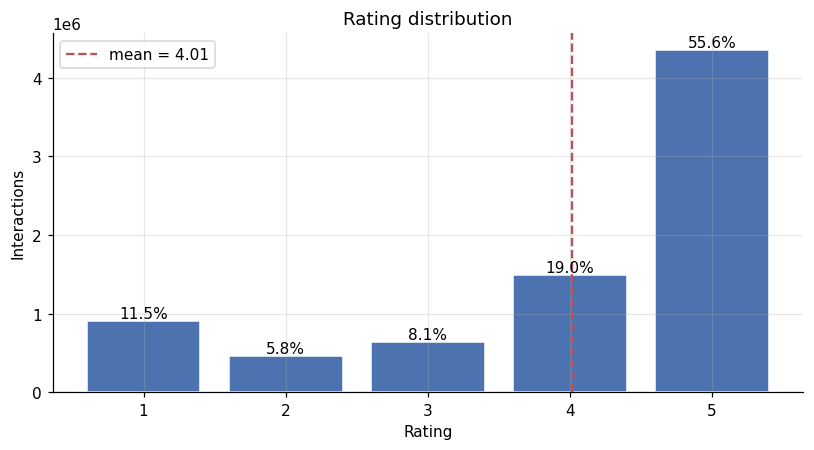

4–5 stars account for 74.55% of ratings; mean = 4.01, median = 5.


In [8]:
# Build the rating distribution from full-file frequency counts, not the five-row preview.
rating_table = pd.DataFrame({
    "rating": [float(v) for v in facts["rating_value_counts"]],
    "count": [int(c) for c in facts["rating_value_counts"].values()],
}).sort_values("rating", ignore_index=True)
# Convert counts to percentages so the chart labels describe rating share.
rating_table["percentage"] = 100 * rating_table["count"] / rating_table["count"].sum()
display(rating_table.style.format({"rating": "{:.0f}", "count": "{:,}", "percentage": "{:.2f}%"}))

# Plot the distribution and mark the overall mean for context.
fig, ax = plt.subplots(figsize=(7.5, 4.2))
# Use one bar per rating value; the five-point scale stays easy to compare.
bars = ax.bar(rating_table["rating"], rating_table["count"], color="#4C72B0", edgecolor="white")
# Label each bar with its share of all ratings.
for bar, pct in zip(bars, rating_table["percentage"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{pct:.1f}%", ha="center", va="bottom")
# Show the mean as a reference without hiding the rating counts.
ax.axvline(facts["rating_mean"], color="#C44E52", linestyle="--", label=f"mean = {facts['rating_mean']:.2f}")
ax.set(title="Rating distribution", xlabel="Rating", ylabel="Interactions", xticks=rating_table["rating"])
ax.legend()
finish_chart(fig)
print(f"4–5 stars account for {rating_table.loc[rating_table['rating'] >= 4, 'percentage'].sum():.2f}% of ratings; "
      f"mean = {facts['rating_mean']:.2f}, median = {facts['rating_median']:.0f}.")

,ratings per user
mean,1.86222
50%,1.00000
75%,2.00000
99%,12.00000
max,520.00000


,bucket,identifiers,ratings_contributed,% of identifiers,% of ratings
0,1,"2,881,832","2,881,832",68.59%,36.83%
1,2,"668,184","1,336,368",15.90%,17.08%
2,3–5,"473,011","1,702,129",11.26%,21.75%
3,6–10,"127,256","932,010",3.03%,11.91%
4,>10,"51,413","972,143",1.22%,12.42%


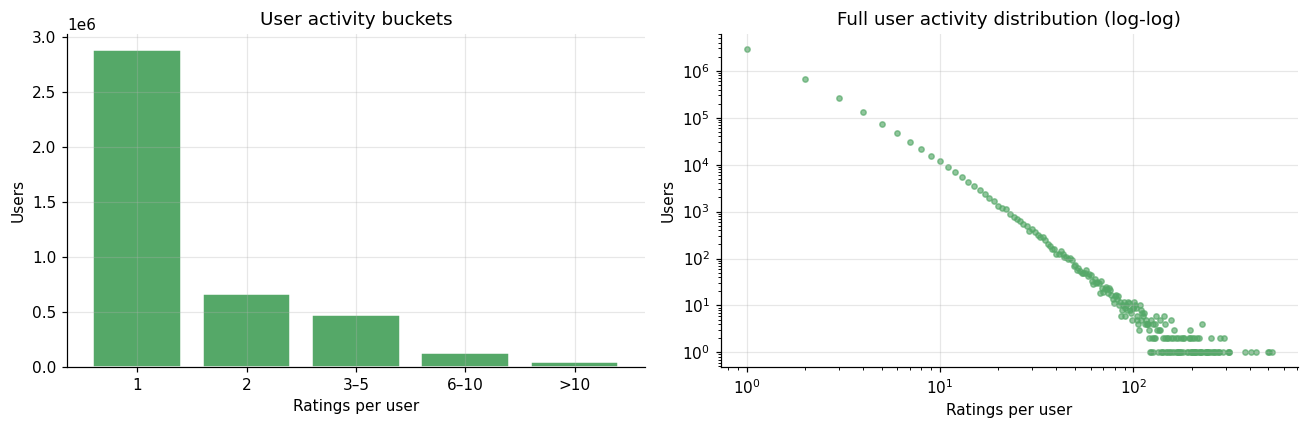

Median user history is 1 rating; 68.59% of users rated exactly one product.


In [9]:
# Summarize user history lengths and group them into activity buckets.
user_summary = describe_from_table(user_activity)
user_buckets = bucket_counts(
    user_activity, [1, 2, 5, 10], ["1", "2", "3–5", "6–10", ">10"]
)
# Show central and upper-tail values; the buckets reveal how activity is distributed.
display(user_summary[["mean", "50%", "75%", "99%", "max"]].to_frame("ratings per user"))
display(user_buckets.style.format({"identifiers": "{:,}", "ratings_contributed": "{:,}",
                                   "% of identifiers": "{:.2f}%", "% of ratings": "{:.2f}%"}))

# Compare bucket counts with the full long-tailed distribution.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(user_buckets["bucket"], user_buckets["identifiers"], color="#55A868", edgecolor="white")
axes[0].set(title="User activity buckets", xlabel="Ratings per user", ylabel="Users")
# Log scales keep rare high-activity users visible alongside the much larger low-activity group.
axes[1].scatter(user_activity["ratings_held"], user_activity["identifiers"], s=12, alpha=.65, color="#55A868")
axes[1].set(xscale="log", yscale="log", title="Full user activity distribution (log-log)",
            xlabel="Ratings per user", ylabel="Users")
finish_chart(fig)
print(f"Median user history is {user_summary['50%']:.0f} rating; "
      f"{user_buckets.loc[0, '% of identifiers']:.2f}% of users rated exactly one product.")

,ratings per product
mean,16.437918
50%,2.000000
75%,7.000000
99%,246.000000
max,18244.000000


,bucket,identifiers,ratings_contributed,% of identifiers,% of ratings
0,1,"179,738","179,738",37.76%,2.30%
1,2,"72,180","144,360",15.16%,1.84%
2,3–5,"84,908","317,837",17.84%,4.06%
3,6–10,"48,279","367,283",10.14%,4.69%
4,11–50,"65,139","1,464,351",13.68%,18.71%
5,51–100,"12,681","891,834",2.66%,11.40%
6,>100,"13,077","4,459,079",2.75%,56.99%


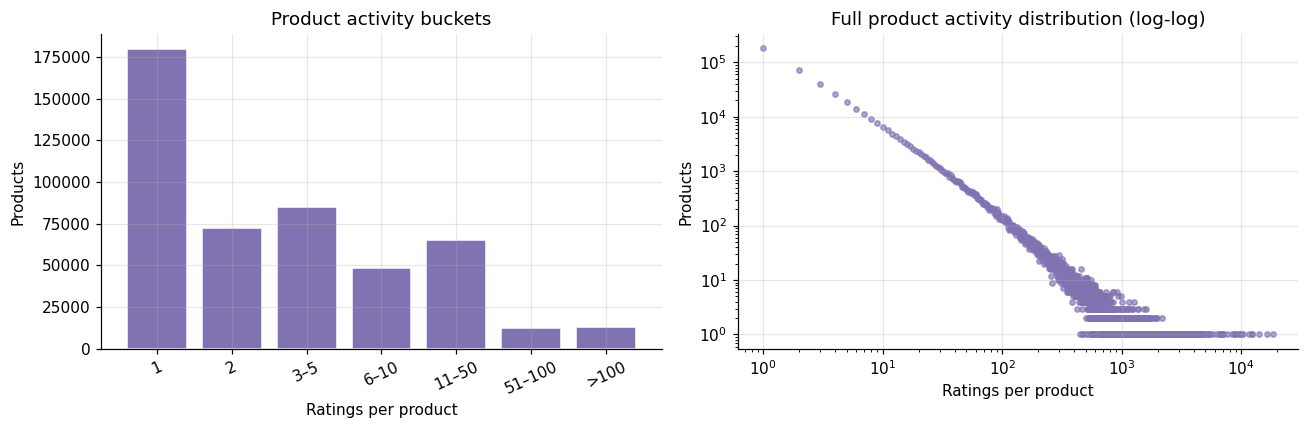

Median product support is 2 ratings; 37.76% of products have one rating.


In [10]:
# Summarize ratings per product using the same weighted activity table.
product_summary = describe_from_table(product_activity)
product_buckets = bucket_counts(
    product_activity, [1, 2, 5, 10, 50, 100], ["1", "2", "3–5", "6–10", "11–50", "51–100", ">100"]
)
# Show typical and high-support products beside the support buckets.
display(product_summary[["mean", "50%", "75%", "99%", "max"]].to_frame("ratings per product"))
display(product_buckets.style.format({"identifiers": "{:,}", "ratings_contributed": "{:,}",
                                      "% of identifiers": "{:.2f}%", "% of ratings": "{:.2f}%"}))

# Plot product support buckets and the long-tail distribution.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(product_buckets["bucket"], product_buckets["identifiers"], color="#8172B2", edgecolor="white")
axes[0].set(title="Product activity buckets", xlabel="Ratings per product", ylabel="Products")
axes[0].tick_params(axis="x", rotation=25)
# Log axes make low-support products and a few highly rated products visible together.
axes[1].scatter(product_activity["ratings_held"], product_activity["identifiers"], s=12, alpha=.65, color="#8172B2")
axes[1].set(xscale="log", yscale="log", title="Full product activity distribution (log-log)",
            xlabel="Ratings per product", ylabel="Products")
finish_chart(fig)
print(f"Median product support is {product_summary['50%']:.0f} ratings; "
      f"{product_buckets.loc[0, '% of identifiers']:.2f}% of products have one rating.")

In [11]:
# Use unique observed pairs as the number of stored matrix entries.
observed = facts["unique_user_product_pairs"]
# The product of users and products is the size of a dense interaction matrix.
possible = facts["total_possible_user_product_combinations"]
density = facts["interaction_density"]
sparsity = facts["sparsity"]
# Show density, sparsity and the memory a dense float64 matrix would need.
display(pd.DataFrame({"value": {
    "Observed interactions": f"{observed:,}",
    "Possible user-product pairs": f"{possible:,}",
    "Interaction density": f"{density * 100:.7f}%",
    "Sparsity": f"{sparsity * 100:.7f}%",
    "Dense float64 matrix size": human_bytes(possible * 8),
}}))
print("The sparse observed-interaction representation is required; a dense matrix is impractical.")

,value
Observed interactions,"7,824,482"
Possible user-product pairs,"2,000,015,699,392"
Interaction density,0.0003912%
Sparsity,99.9996088%
Dense float64 matrix size,"14,901.28 GiB"


The sparse observed-interaction representation is required; a dense matrix is impractical.


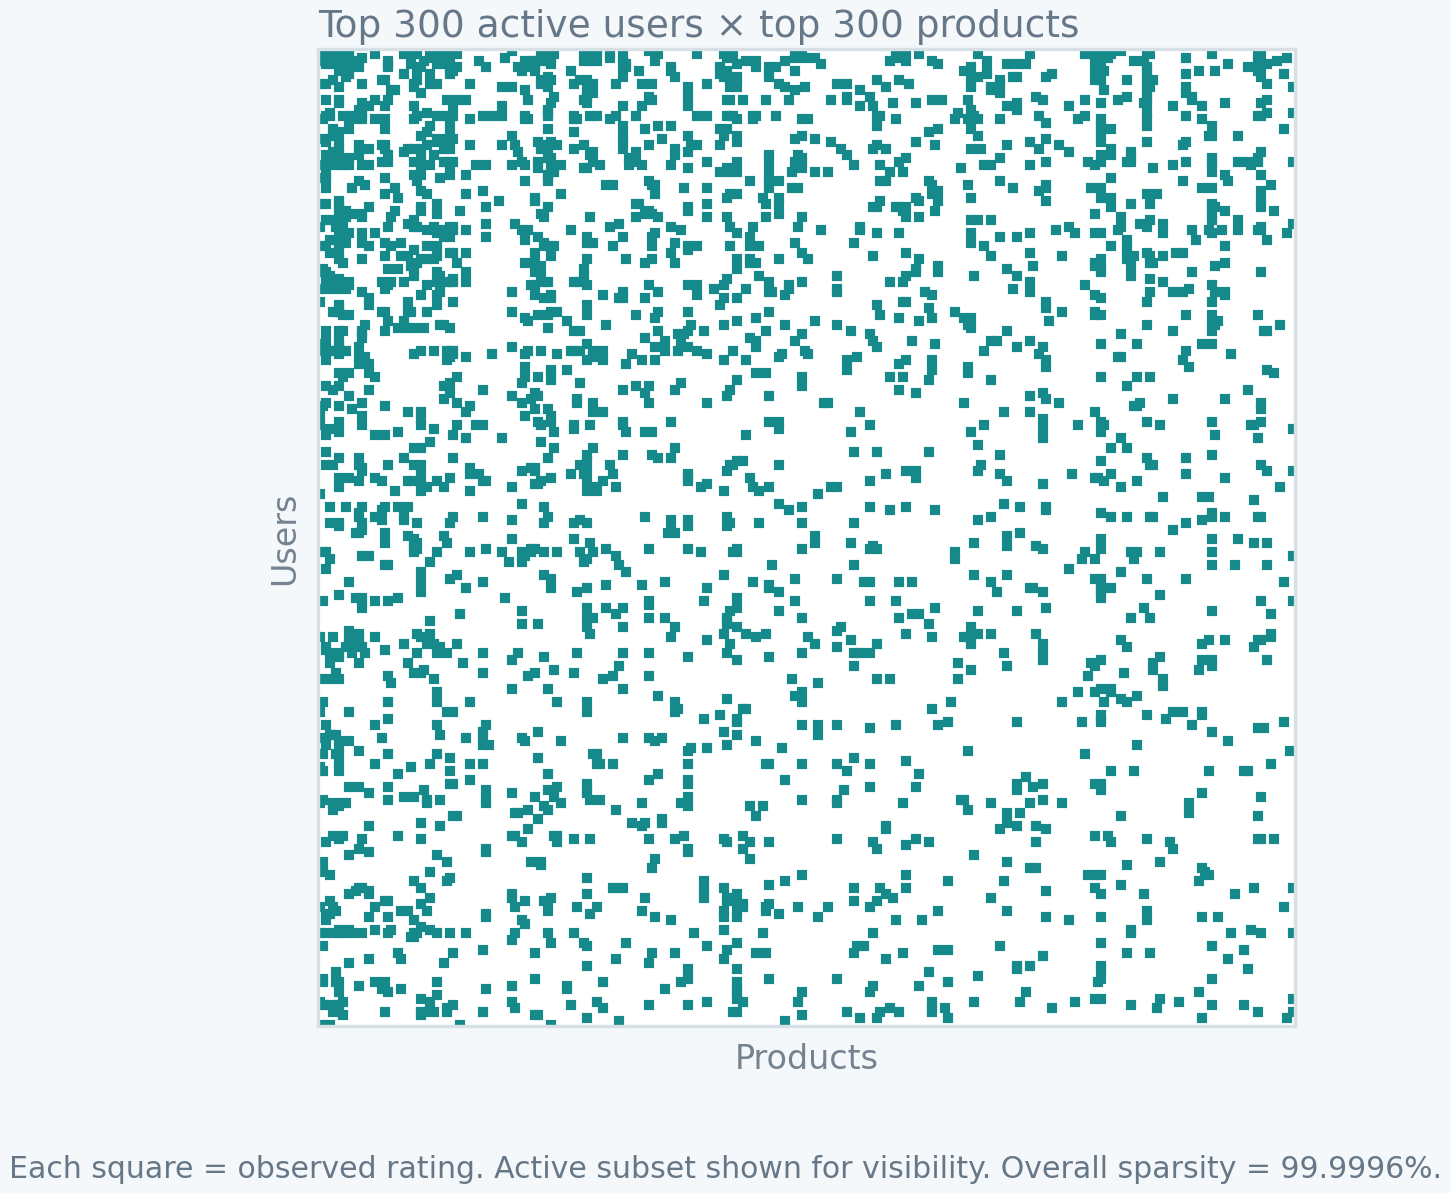

In [33]:
# Stream ratings in chunks, then plot only the active 300-by-300 subset.
from pathlib import Path
import sqlite3
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from IPython.display import display

ratings_path = Path(DATA_PATH)
subset_size = 300
column_names = ["userId", "productId", "Rating", "timestamp"]

# Temporary SQLite keeps global activity counts on disk instead of storing every ID in RAM.
with tempfile.TemporaryDirectory(prefix="p704_spy_") as staging:
    connection = sqlite3.connect(Path(staging) / "activity.sqlite")
    connection.executescript("""
        PRAGMA journal_mode = OFF;
        PRAGMA synchronous = OFF;
        PRAGMA temp_store = FILE;
        PRAGMA cache_size = -262144;
        CREATE TABLE interactions (userId TEXT, productId TEXT);
    """)

    reader = pd.read_csv(
        ratings_path, header=None, names=column_names,
        usecols=["userId", "productId"],
        dtype={"userId": "string", "productId": "string"},
        keep_default_na=False, na_filter=False, chunksize=CHUNK_ROWS,
    )
    for chunk in reader:
        connection.executemany(
            "INSERT INTO interactions VALUES (?, ?)",
            chunk[["userId", "productId"]].itertuples(index=False, name=None),
        )
    connection.commit()

    # Rank users and products by their full-data interaction counts.
    top_user_counts = connection.execute(
        "SELECT userId, COUNT(*) FROM interactions GROUP BY userId "
        "ORDER BY COUNT(*) DESC, userId LIMIT ?", (subset_size,)
    ).fetchall()
    top_product_counts = connection.execute(
        "SELECT productId, COUNT(*) FROM interactions GROUP BY productId "
        "ORDER BY COUNT(*) DESC, productId LIMIT ?", (subset_size,)
    ).fetchall()
    # Keep both axes ordered from the highest activity/support down.
    top_users = [user_id for user_id, _ in top_user_counts]
    top_products = [product_id for product_id, _ in top_product_counts]

    # Fetch only observed pairs whose user and product are both in the selected subset.
    user_slots = ",".join("?" for _ in top_users)
    product_slots = ",".join("?" for _ in top_products)
    query = (
        f"SELECT userId, productId FROM interactions "
        f"WHERE userId IN ({user_slots}) AND productId IN ({product_slots}) "
        "GROUP BY userId, productId"
    )
    observed_pairs = connection.execute(query, top_users + top_products).fetchall()
    connection.close()

# Store presence only; rating values are not read or encoded in this matrix.
user_positions = {user_id: position for position, user_id in enumerate(top_users)}
product_positions = {product_id: position for position, product_id in enumerate(top_products)}
row_indices = [user_positions[user_id] for user_id, _ in observed_pairs]
column_indices = [product_positions[product_id] for _, product_id in observed_pairs]
presence = coo_matrix(
    (np.ones(len(row_indices), dtype=np.uint8), (row_indices, column_indices)),
    shape=(len(top_users), len(top_products)),
).tocsr()
presence.data[:] = 1

# A sparse spy plot shows observed interactions without allocating a dense matrix.
fig, ax = plt.subplots(figsize=(5.4, 4.4), facecolor="#F5F8FA")
ax.set_facecolor("white")
ax.spy(presence, marker="s", markersize=1.5, color="#168A8A", origin="upper")
ax.set_title("Top 300 active users × top 300 products", loc="left", fontsize=9,
             fontweight="normal", color="#667788", pad=3)
ax.set_xlabel("Products", color="#758391", fontsize=8, labelpad=4)
ax.set_ylabel("Users", color="#758391", fontsize=8, labelpad=4)
ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)
for spine in ax.spines.values():
    spine.set_color("#D6E0E5")

fig.text(0.5, 0.045,
         "Each square = observed rating. Active subset shown for visibility. Overall sparsity = 99.9996%.",
         ha="center", fontsize=7.2, color="#667788")
fig.subplots_adjust(left=0.12, right=0.98, top=0.90, bottom=0.16)

output_path = Path("sparsity_visualization.png")
fig.savefig(output_path, dpi=300, bbox_inches="tight", pad_inches=0.03,
            facecolor=fig.get_facecolor())
display(fig)
plt.close(fig)

# Export the same sparse matrix in a compact landscape layout for the slide panel.
ppt_fig, ppt_ax = plt.subplots(figsize=(8.0, 5.0), facecolor="#F5F8FA")
ppt_ax.set_facecolor("white")
ppt_ax.spy(presence, marker="s", markersize=1.5, color="#168A8A", origin="upper")
ppt_ax.set_aspect("auto")
ppt_ax.set_title("Top 300 active users × top 300 products", loc="left", fontsize=8.5,
                 fontweight="normal", color="#74818D", pad=3)
ppt_ax.set_xlabel("Products", color="#7A8792", fontsize=8, labelpad=3)
ppt_ax.set_ylabel("Users", color="#7A8792", fontsize=8, labelpad=3)
ppt_ax.set_xticks([])
ppt_ax.set_yticks([])
ppt_ax.grid(False)
for spine in ppt_ax.spines.values():
    spine.set_color("#D6E0E5")
ppt_fig.subplots_adjust(left=0.07, right=0.995, top=0.93, bottom=0.07)
ppt_fig.savefig("sparsity_visualization_ppt.png", dpi=300, bbox_inches="tight",
                pad_inches=0.025, facecolor=ppt_fig.get_facecolor())
plt.close(ppt_fig)



## 6. Key EDA Findings

The file contains 7,824,482 interactions, but the median user history is 1 rating and the median product support is 2. User-product density is about 0.000391221%; a dense matrix would require roughly 14,901 GiB, so sparse representations are necessary. Very limited history is insufficient for this behavioural evaluation setup, but it is not the same as a true cold-start user with no history.

In [12]:
# Keep the EDA conclusion to the data-quality, preference and sparsity facts used downstream.
eda_findings = [
    "Data quality checks found no missing values, duplicate pairs or invalid ratings; IDs must remain text.",
    f"Ratings are concentrated at the high end ({rating_table.loc[rating_table['rating'] >= 4, 'percentage'].sum():.1f}% are 4–5), "
    f"but histories are short (median user: {user_summary['50%']:.0f}; median product: {product_summary['50%']:.0f}).",
    f"The matrix is {sparsity * 100:.5f}% sparse, so this notebook keeps only observed triples and uses no timestamp.",
]
# Print each concise finding from the tables above.
for finding in eda_findings:
    print(f"• {finding}")

• Data quality checks found no missing values, duplicate pairs or invalid ratings; IDs must remain text.
• Ratings are concentrated at the high end (74.6% are 4–5), but histories are short (median user: 1; median product: 2).
• The matrix is 99.99961% sparse, so this notebook keeps only observed triples and uses no timestamp.


## 7. Modelling Dataset Preparation

The interaction threshold controls modelling eligibility; it does not clean or remove rows from the source data. The threshold comparison is ≥2: 1,319,864 users / 63.17% of interactions; ≥3: 651,680 / 46.09%; ≥5: 254,064 / 29.15%; and ≥10: 63,175 / 13.93%. We use ≥5 as a practical balance between enough history for behavioural features and holdout evaluation and retaining a meaningful user population—not as a mathematically optimal cutoff.

In [13]:
# This modelling eligibility rule keeps users with enough history; it does not delete or repair raw data.
MIN_USER_INTERACTIONS = 5
# Use the same recommendation list length for examples and all evaluation approaches.
TOP_N = 10
# Require at least ten training ratings before a product can be a cluster candidate.
MIN_SUPPORT = 10
# Exclude products with a low cluster-average rating.
MIN_CLUSTER_MEAN_RATING = 4.0
# Require at least 60% of cluster ratings to be positive (4 or 5 stars).
MIN_CLUSTER_POSITIVE_RATE = 0.60
# Cap each pre-ranked list so user-level seen-item filtering stays efficient.
CANDIDATE_POOL = 1_000
# Reuse one fixed sample for scalable, directly comparable clustering metrics.
SAMPLE_USERS = 10_000

total_users = sum(user_levels.values())
total_interactions = sum(k * v for k, v in user_levels.items())
# Estimate how many users and interactions each candidate history threshold would retain.
threshold_rows = []
# Use the count-of-counts table to compare thresholds without rereading individual rows.
for threshold in [2, 3, 5, 10]:
    users_retained = sum(count for level, count in user_levels.items() if level >= threshold)
    interactions_retained = sum(level * count for level, count in user_levels.items()
                                if level >= threshold)
    threshold_rows.append({
        "minimum interactions": threshold,
        "users retained": users_retained,
        "interactions retained": interactions_retained,
    })
threshold_table = pd.DataFrame(threshold_rows)
# Report retained shares as percentages while leaving counts as integers.
threshold_table["% users"] = 100 * threshold_table["users retained"] / total_users
threshold_table["% interactions"] = 100 * threshold_table["interactions retained"] / total_interactions
display(threshold_table.style.format({"users retained": "{:,}", "interactions retained": "{:,}",
                                       "% users": "{:.2f}%", "% interactions": "{:.2f}%"}).hide(axis="index"))

minimum interactions,users retained,interactions retained,% users,% interactions
2,"1,319,864","4,942,650",31.41%,63.17%
3,"651,680","3,606,282",15.51%,46.09%
5,"254,064","2,281,128",6.05%,29.15%
10,"63,175","1,089,763",1.50%,13.93%


In [14]:
# Read only eligible users into memory after the disk-backed threshold join.
def build_modelling_subset(path=DATA_PATH, min_interactions=MIN_USER_INTERACTIONS,
                           chunk_rows=CHUNK_ROWS):
    """Return users meeting the modelling-history threshold.

Args:
    path: Headerless ratings CSV location.
    min_interactions: Minimum number of rows required per user.
    chunk_rows: Rows read per CSV chunk.
Returns:
    A DataFrame containing eligible interactions with compact categorical IDs.
"""
    # Filter eligible users on disk to avoid loading the full ratings table into memory.
    started = time.time()
    with tempfile.TemporaryDirectory(prefix="p704_model_") as staging:
        con = sqlite3.connect(Path(staging) / "model.sqlite")
        # These SQLite settings speed up a disposable staging table and keep temporary operations on disk.
        con.executescript("""
            PRAGMA journal_mode=OFF; PRAGMA synchronous=OFF;
            PRAGMA temp_store=FILE; PRAGMA cache_size=-262144;
            CREATE TABLE ratings (userId TEXT, productId TEXT, Rating REAL);
        """)
        # Read only the three model columns in chunks; timestamp is not used by the recommender.
        reader = pd.read_csv(
            path, header=None, names=COLUMNS, usecols=["userId", "productId", "Rating"],
            dtype={"userId": "string", "productId": "string", "Rating": "float64"},
            keep_default_na=False, na_filter=False, chunksize=chunk_rows,
        )
        # Insert each bounded CSV piece into the temporary table.
        for chunk in reader:
            con.executemany(
                "INSERT INTO ratings VALUES (?,?,?)",
                zip(chunk["userId"].tolist(), chunk["productId"].tolist(), chunk["Rating"].tolist()),
            )
        con.commit()
        # Count each user's rows on disk so eligibility is based on the full dataset.
        con.execute("CREATE TABLE user_counts AS SELECT userId AS id, COUNT(*) c "
                    "FROM ratings GROUP BY userId")
        # Keep IDs meeting the selected modelling-history threshold.
        con.execute(f"CREATE TABLE eligible AS SELECT id FROM user_counts WHERE c >= {min_interactions}")
        # Index the eligible IDs so the subsequent join can find matching rows efficiently.
        con.execute("CREATE UNIQUE INDEX ix_eligible ON eligible(id)")
        # Read the eligible subset back in manageable chunks instead of loading all raw users.
        parts = list(pd.read_sql_query(
            "SELECT r.userId, r.productId, r.Rating FROM ratings r JOIN eligible e ON r.userId = e.id",
            con, chunksize=500_000,
        ))
        con.close()

    # Combine only the eligible chunks into the modelling DataFrame.
    df = pd.concat(parts, ignore_index=True)
    # Categorical IDs retain their text labels while using less memory and enabling integer-code maps.
    df["userId"] = df["userId"].astype("category")
    df["productId"] = df["productId"].astype("category")
    # Ratings 1–5 fit in int8, reducing the in-memory modelling table.
    df["Rating"] = df["Rating"].astype("int8")
    print(f"Extracted {len(df):,} rows in {time.time() - started:.1f}s")
    return df


# Create the modelling population without changing the source CSV.
model_df = build_modelling_subset()
print(f"Modelling population: {model_df['userId'].nunique():,} users, "
      f"{len(model_df):,} interactions, {model_df['productId'].nunique():,} products")
print(f"In-memory size: {model_df.memory_usage(deep=True).sum() / 1024**2:,.1f} MiB")
# Protect product IDs with leading zeros from accidental numeric conversion.
assert any(str(p).startswith("0") for p in model_df["productId"].cat.categories), "Leading-zero IDs changed"

Extracted 2,281,128 rows in 34.3s
Modelling population: 254,064 users, 2,281,128 interactions, 284,800 products
In-memory size: 66.9 MiB


**Observation:** The ≥5 rule retains 254,064 users and 29.15% of interactions. It trades some population coverage for enough per-user history to form behavioural features and a positive holdout.

## 8. Positive Holdout Evaluation Setup

For each eligible user, one interaction rated 4 or 5 is held out as the relevant target; all remaining interactions form training data. Behavioural features, product rankings, and SVD representations are built from training rows only, preventing the target from leaking into the model. Warm targets occur in the training catalogue; cold targets do not and are tracked separately.

In [15]:
# Hold out one positive target per user; keep these rows out of training features.
# Only 4- and 5-star interactions count as relevant positive targets.
positive_rows = model_df.loc[model_df["Rating"] >= 4]
positive_eval_users = positive_rows["userId"].nunique()
# Sample one positive target per user with the fixed seed; all remaining rows become training data.
test_df = positive_rows.groupby("userId", observed=True).sample(n=1, random_state=RANDOM_STATE).copy()
# Remove held-out rows before calculating any user features or recommendation statistics.
train_df = model_df.drop(test_df.index).copy()
# Check how much history remains per user after the holdout.
train_sizes = train_df.groupby("userId", observed=True).size()

# Separate warm targets represented in training from cold targets unavailable to recommend.
# Build the recommendable catalogue from training products only.
train_catalogue = set(train_df["productId"].astype(str).unique())
# Mark targets present in training as warm; products absent from training are cold and unavailable.
warm_mask = test_df["productId"].astype(str).isin(train_catalogue)
warm_test_df = test_df.loc[warm_mask].copy()
cold_test_df = test_df.loc[~warm_mask].copy()

# Summarize modelling users, training rows and warm/cold positive targets.
split_summary = pd.DataFrame([
    {"measure": "Modelling users (>=5 interactions)", "value": f"{model_df['userId'].nunique():,}"},
    {"measure": "Users eligible for positive-item evaluation", "value": f"{positive_eval_users:,}"},
    {"measure": "Training interactions", "value": f"{len(train_df):,}"},
    {"measure": "Held-out positive interactions", "value": f"{len(test_df):,}"},
    {"measure": "Warm held-out positives", "value": f"{len(warm_test_df):,}"},
    {"measure": "Cold held-out positives", "value": f"{len(cold_test_df):,}"},
    {"measure": "Cold-item share", "value": f"{100 * len(cold_test_df) / len(test_df):.3f}%"},
])
display(split_summary.style.hide(axis="index"))

# Check that the split neither loses nor duplicates modelling interactions.
assert len(train_df) + len(test_df) == len(model_df)
# Protect against a training row leaking into the holdout.
assert train_df.index.intersection(test_df.index).empty
# Verify every held-out target is relevant under the positive-item definition.
assert (test_df["Rating"] >= 4).all()
# Verify each eligible user retains at least four training ratings.
assert train_sizes.min() >= MIN_USER_INTERACTIONS - 1
# Ensure the warm evaluation targets can actually be recommended.
assert set(warm_test_df["productId"].astype(str)).issubset(train_catalogue)
# Ensure cold targets are genuinely absent from the training catalogue.
assert set(cold_test_df["productId"].astype(str)).isdisjoint(train_catalogue)
print(f"Every modelled user retains at least {train_sizes.min()} training interactions.")

measure,value
Modelling users (>=5 interactions),"254,064"
Users eligible for positive-item evaluation,"252,723"
Training interactions,"2,028,405"
Held-out positive interactions,"252,723"
Warm held-out positives,"237,187"
Cold held-out positives,"15,536"
Cold-item share,6.147%


Every modelled user retains at least 4 training interactions.


**Observation:** The split yields 252,723 users with a positive held-out target: 237,187 warm targets and 15,536 cold targets (6.147%). Cold targets are impossible to retrieve from a training-only catalogue, so they count as misses in overall Hit Rate rather than being mixed into warm-item performance.

## 9. Behavioural Feature Engineering

The training-only profile uses `rating_count`, `log_rating_count`, `mean_rating`, `rating_std`, `positive_ratio`, and `negative_ratio`; raw IDs are not clustering features. Because user activity is highly skewed, `log1p` reduces the influence of very active users while retaining activity information. An undefined standard deviation is filled with zero to represent no measurable spread when history is insufficient, keeping the feature matrix usable by the scaler.

In [16]:
# Build every user feature from training interactions only.
# Aggregate training ratings by user so the holdout cannot influence a cluster.
grouped = train_df.groupby("userId", observed=True)["Rating"]
# Build one row per eligible user from six behaviour measures.
user_features = pd.DataFrame({
    # Rating count captures user activity in the training set.
    "rating_count": grouped.size(),
    # Mean rating summarizes the user's average preference.
    "mean_rating": grouped.mean(),
    # Rating spread captures consistency; fill a missing standard deviation with zero.
    "rating_std": grouped.std().fillna(0.0),
})
# Log1p compresses the long activity tail while preserving zero and ordering.
user_features["log_rating_count"] = np.log1p(user_features["rating_count"])
# Mark 4–5 as positive and 1–2 as negative; a rating of 3 is neither.
flags = train_df.assign(is_positive=(train_df["Rating"] >= 4), is_negative=(train_df["Rating"] <= 2))
# Measure the share of each user's training ratings that are positive.
user_features["positive_ratio"] = flags.groupby("userId", observed=True)["is_positive"].mean()
# Measure the share rated 1–2 so more critical users remain distinguishable.
user_features["negative_ratio"] = flags.groupby("userId", observed=True)["is_negative"].mean()
# Release the temporary row-level flags after both ratios are calculated.
del flags
# Keep a fixed feature order for scaling, clustering and interpretation.
user_features = user_features[["rating_count", "log_rating_count", "mean_rating", "rating_std",
                               "positive_ratio", "negative_ratio"]]
# Check that aggregation produced exactly one profile per training user.
assert len(user_features) == train_df["userId"].nunique()
# Catch missing feature values before StandardScaler and KMeans.
assert not user_features.isna().any().any()
display(user_features.describe().T.style.format("{:.3f}"))

,count,mean,std,min,25%,50%,75%,max
rating_count,254064.000,7.984,8.647,4.000,4.000,6.000,8.000,519.000
log_rating_count,254064.000,2.036,0.480,1.609,1.609,1.946,2.197,6.254
mean_rating,254064.000,4.070,0.768,1.000,3.667,4.222,4.667,5.000
rating_std,254064.000,1.001,0.598,0.000,0.516,1.000,1.499,2.309
positive_ratio,254064.000,0.749,0.245,0.000,0.600,0.800,1.000,1.000
negative_ratio,254064.000,0.151,0.198,0.000,0.000,0.083,0.250,1.000


**Observation:** These features summarize training activity, rating level/spread, and preference shares; raw IDs do not enter clustering. The log count limits the effect of the long activity tail, and a missing standard deviation is represented as zero spread.

## 10. Feature Scaling

KMeans assigns users by distance, so feature scale affects which dimensions shape a cluster. Here activity counts, rating values, and preference ratios have different ranges; standardizing the five training-derived features prevents large numeric scales from dominating distance. The original feature values remain available for interpreting the fitted clusters.

In [17]:
# Use log activity rather than raw counts, alongside rating and preference features.
CLUSTER_FEATURES = ["log_rating_count", "mean_rating", "rating_std", "positive_ratio", "negative_ratio"]
# KMeans uses distances, so features with different numeric ranges need standardization.
scaler = StandardScaler()
# Fit scaling only on training-derived user features, then create the clustering matrix.
X_scaled = scaler.fit_transform(user_features[CLUSTER_FEATURES])
# Use a seeded generator so the metric sample is repeatable.
rng = np.random.default_rng(RANDOM_STATE)
# Select the same 10,000 user rows for later Approach A and B metric comparisons.
metric_sample = rng.choice(len(X_scaled), size=SAMPLE_USERS, replace=False)
# Keep the sampled scaled rows for metrics that would be expensive on every user.
X_sample = X_scaled[metric_sample]
print(f"Scaled training-feature matrix: {X_scaled.shape}; metric sample: {SAMPLE_USERS:,} users.")

Scaled training-feature matrix: (254064, 5); metric sample: 10,000 users.


**Observation:** The scaled input has 254,064 users and five clustering features. KMeans uses these standardized values; the unscaled training summaries remain available for cluster interpretation.

## 11. KMeans Clustering and k Selection

We compare k=2 through k=8 using inertia, Silhouette, Davies–Bouldin, and Calinski–Harabasz. Silhouette uses the fixed reproducible 10,000-user sample; the other reported KMeans metrics use the full eligible population. The metrics describe different aspects of compactness and separation, so selection considers their pattern alongside segment interpretability.

In [18]:
# Fit each candidate k on all users; use the fixed sample for Silhouette.
k_rows = []
# Test each candidate cluster count from 2 through 8.
for k in range(2, 9):
    # Fit each candidate on the full eligible-user feature matrix with a reproducible initialization.
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
    labels = km.labels_
    k_rows.append({
        # Inertia is within-cluster squared distance; use its bend as an elbow, not as a standalone optimum.
        "k": k, "inertia": km.inertia_,
        # Silhouette measures cohesion and separation; higher is better, and this score uses the fixed sample.
        "silhouette (10k sample)": silhouette_score(X_sample, labels[metric_sample]),
        # Davies–Bouldin summarizes overlap; lower is better, calculated here on all users.
        "davies_bouldin (full)": davies_bouldin_score(X_scaled, labels),
        # Calinski–Harabasz compares between- and within-cluster spread; higher is better, on all users.
        "calinski_harabasz (full)": calinski_harabasz_score(X_scaled, labels),
    })
k_table = pd.DataFrame(k_rows)
display(k_table.style.format({"inertia": "{:,.0f}", "silhouette (10k sample)": "{:.4f}",
                              "davies_bouldin (full)": "{:.4f}", "calinski_harabasz (full)": "{:,.0f}"}).hide(axis="index"))

[local Python environment]\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "[local Python environment]\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "[local Python environment]\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "[local Python environment]\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^

k,inertia,silhouette (10k sample),davies_bouldin (full),calinski_harabasz (full)
2,"693,351",0.4086,0.9785,"211,416"
3,"508,284",0.3602,1.0584,"190,449"
4,"376,297",0.3923,0.9438,"201,203"
5,"318,305",0.3447,1.0113,"189,965"
6,"277,307",0.3416,1.0466,"181,952"
7,"248,508",0.3508,1.0369,"174,105"
8,"224,304",0.3552,0.9816,"169,252"


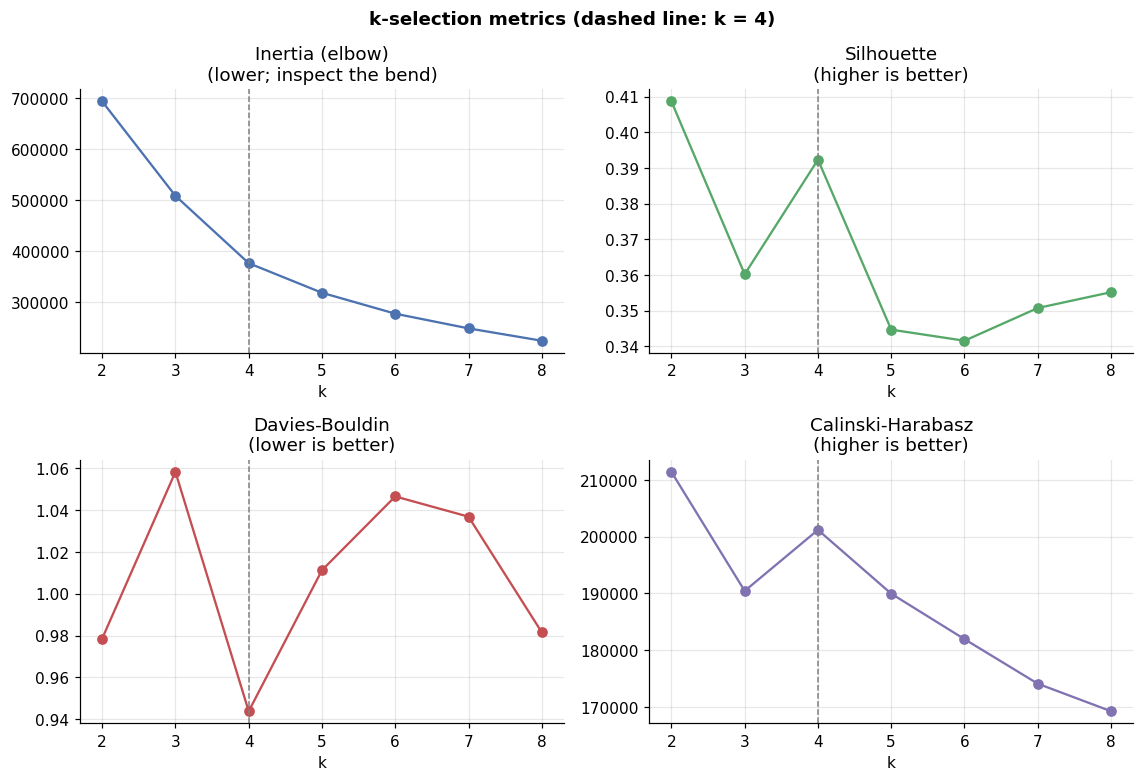

In [19]:
# Keep each metric's display name, direction and color together for the four-panel chart.
specs = [
    ("inertia", "Inertia (elbow)", "lower; inspect the bend", "#4C72B0"),
    ("silhouette (10k sample)", "Silhouette", "higher is better", "#55A868"),
    ("davies_bouldin (full)", "Davies-Bouldin", "lower is better", "#C44E52"),
    ("calinski_harabasz (full)", "Calinski-Harabasz", "higher is better", "#8172B2"),
]
# A 2x2 layout keeps the k-selection metrics readable without a very wide row.
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.2))
# Plot one metric per axis using its table values and direction note.
for ax, (column, title, note, color) in zip(axes.ravel(), specs):
    ax.plot(k_table["k"], k_table[column], marker="o", color=color)
    # Mark the selected k=4 on every chart so metric preferences are easy to compare.
    ax.axvline(4, color="grey", linestyle="--", linewidth=1)
    ax.set(title=f"{title}\n({note})", xlabel="k")
    ax.ticklabel_format(axis="y", style="plain")
fig.suptitle("k-selection metrics (dashed line: k = 4)", fontweight="bold")
finish_chart(fig)

The elbow is around k=4 and Davies–Bouldin is lowest at k=4, while Silhouette and Calinski–Harabasz favour k=2. We retain k=4 as a practical multi-criteria choice that provides four interpretable segments and assigns every eligible user; it is not the winner of every metric.

## 12. MiniBatchKMeans / DBSCAN Comparison

MiniBatchKMeans checks whether a faster centroid method retains similar clustering quality; DBSCAN adds a density-based comparison. KMeans and MiniBatchKMeans are fitted on all eligible users and scored on the fixed 10,000-user sample, while DBSCAN is fitted only on that sample. DBSCAN quality metrics exclude noise points, so they are not directly equivalent to KMeans metrics that cover all sampled users.

In [20]:
# Fit DBSCAN on the fixed sample; score all assigned non-noise points, including core and border points.
dbscan_rows = []
# Epsilon sets the neighbourhood radius; the grid shows how cluster shape changes with scale.
for eps in [0.3, 0.5, 0.7, 1.0]:
    # Min_samples is the local density required for a point to be a core point.
    for min_samples in [5, 10, 20]:
        started = time.time()
        # Fit DBSCAN only on the fixed 10,000-user sample; -1 labels denote noise.
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit(X_sample).labels_
        # This mask keeps every assigned point (including border points) and removes noise from quality scores.
        core = labels != -1
        # Count real clusters while excluding the possible -1 noise label.
        n_clusters = len(set(labels)) - int(-1 in labels)
        row = {"eps": eps, "min_samples": min_samples, "clusters": n_clusters,
               "noise %": 100 * (~core).mean(), "silhouette": np.nan,
               "davies_bouldin": np.nan, "fit seconds": time.time() - started}
        # Silhouette and Davies–Bouldin require at least two clusters among the scored non-noise points.
        if n_clusters >= 2 and core.sum() > 1:
            row["silhouette"] = silhouette_score(X_sample[core], labels[core])
            row["davies_bouldin"] = davies_bouldin_score(X_sample[core], labels[core])
        dbscan_rows.append(row)
dbscan_grid = pd.DataFrame(dbscan_rows)
display(dbscan_grid.style.format({"noise %": "{:.2f}%", "silhouette": "{:.4f}",
                                  "davies_bouldin": "{:.4f}", "fit seconds": "{:.2f}"},
                                 na_rep="not defined").hide(axis="index"))

# Retain k=4: the elbow and Davies–Bouldin support it, and four segments are interpretable.
K_SELECTED = 4
# Fit both centroid models on all users and compare their metrics on the same sample.
comparison_rows = []
# Compare KMeans with MiniBatchKMeans using the same k and random seed.
for name, model in [
    ("KMeans", KMeans(n_clusters=K_SELECTED, random_state=RANDOM_STATE, n_init=10)),
    ("MiniBatchKMeans", MiniBatchKMeans(n_clusters=K_SELECTED, random_state=RANDOM_STATE,
                                         n_init=10, batch_size=4096)),
]:
    started = time.time()
    # Fit both centroid models on all users, then reuse their labels for the shared metric sample.
    labels_full = model.fit(X_scaled).labels_
    fit_seconds = time.time() - started
    labels_sample = labels_full[metric_sample]
    comparison_rows.append({
        "method": f"{name} (k={K_SELECTED})", "fitted on": f"all {len(X_scaled):,} users",
        "clusters": K_SELECTED, "noise %": 0.0,
        "silhouette": silhouette_score(X_sample, labels_sample),
        "davies_bouldin": davies_bouldin_score(X_sample, labels_sample),
        "calinski_harabasz": calinski_harabasz_score(X_sample, labels_sample),
        "fit seconds": fit_seconds,
    })
    # Keep full KMeans labels for Approach A profiles and recommendations.
    if name == "KMeans":
        kmeans_model, kmeans_labels = model, labels_full

# Choose a representative DBSCAN solution only from runs with 2–4 clusters.
broad_dbscan = dbscan_grid[(dbscan_grid["clusters"] >= 2) & (dbscan_grid["clusters"] <= 4)].copy()
# If no run has 2–4 clusters, fall back to configurations with defined separation metrics.
if broad_dbscan.empty:
    broad_dbscan = dbscan_grid.dropna(subset=["silhouette"]).copy()
# Prefer lower noise, then higher Silhouette, to show a broad DBSCAN comparison.
representative_dbscan = broad_dbscan.sort_values(["noise %", "silhouette"], ascending=[True, False]).iloc[0]
# Refit the selected grid setting on the same sample for the comparison table.
db_labels = DBSCAN(eps=representative_dbscan["eps"],
                   min_samples=int(representative_dbscan["min_samples"])).fit(X_sample).labels_
# Exclude noise again when computing DBSCAN's Calinski–Harabasz score.
db_core = db_labels != -1
comparison_rows.append({
    "method": (f"DBSCAN (eps={representative_dbscan['eps']}, "
               f"min_samples={int(representative_dbscan['min_samples'])})"),
    "fitted on": f"{SAMPLE_USERS:,}-user sample", "clusters": int(representative_dbscan["clusters"]),
    "noise %": representative_dbscan["noise %"], "silhouette": representative_dbscan["silhouette"],
    "davies_bouldin": representative_dbscan["davies_bouldin"],
    "calinski_harabasz": calinski_harabasz_score(X_sample[db_core], db_labels[db_core]),
    "fit seconds": representative_dbscan["fit seconds"],
})
algorithm_comparison = pd.DataFrame(comparison_rows)
display(algorithm_comparison.style.format({"noise %": "{:.2f}%", "silhouette": "{:.4f}",
                                            "davies_bouldin": "{:.4f}", "calinski_harabasz": "{:,.0f}",
                                            "fit seconds": "{:.2f}"}).hide(axis="index"))

eps,min_samples,clusters,noise %,silhouette,davies_bouldin,fit seconds
0.300000,5,217,10.16%,0.4458,0.5726,0.15
0.300000,10,129,19.82%,0.5294,0.5705,0.09
0.300000,20,75,32.45%,0.6124,0.5899,0.09
0.500000,5,65,1.51%,-0.0874,0.7316,0.17
0.500000,10,51,3.76%,-0.0779,0.7527,0.15
0.500000,20,32,9.19%,-0.0672,0.7220,0.16
0.700000,5,9,0.25%,-0.1636,0.7061,0.23
0.700000,10,7,0.51%,-0.1513,0.7328,0.32
0.700000,20,8,1.22%,-0.1203,0.7762,0.40
1.000000,5,1,0.09%,not defined,not defined,0.78


method,fitted on,clusters,noise %,silhouette,davies_bouldin,calinski_harabasz,fit seconds
KMeans (k=4),"all 254,064 users",4,0.00%,0.3923,0.9457,"7,932",1.34
MiniBatchKMeans (k=4),"all 254,064 users",4,0.00%,0.3845,0.9770,"7,727",0.28
"DBSCAN (eps=0.7, min_samples=5)","10,000-user sample",9,0.25%,-0.1636,0.7061,262,0.23


MiniBatchKMeans is much faster with similar sample-level cluster quality. DBSCAN is sample-only: smaller eps values create many clusters and noise, around 0.7 gives roughly 7–9 poorly separated clusters, and eps=1.0 collapses toward one cluster. DBSCAN is not selected because these settings do not provide the desired complete, interpretable assignment.

## 13. Cluster Interpretation

Profiles are summarized with the original training behavioural statistics, which remain meaningful in rating and activity units; scaled values and IDs are not used to name groups. The labels below are descriptive summaries of the fitted groups, not categories assigned to users before clustering.

,users,mean_rating_count,median_rating_count,mean_rating,mean_rating_std,mean_positive_ratio,mean_negative_ratio,% of users,label
cluster,,,,,,,,,
0,"81,915",6.14,6.0,3.813,1.486,0.663,0.209,32.24%,lower-activity / mixed raters
1,"99,237",5.57,5.0,4.674,0.442,0.941,0.000,39.06%,lower-activity / positive raters
2,"40,418",19.36,15.0,4.304,0.996,0.825,0.086,15.91%,higher-activity / positive raters
3,"32,494",5.87,5.0,2.583,1.490,0.287,0.549,12.79%,lower-activity / more critical raters


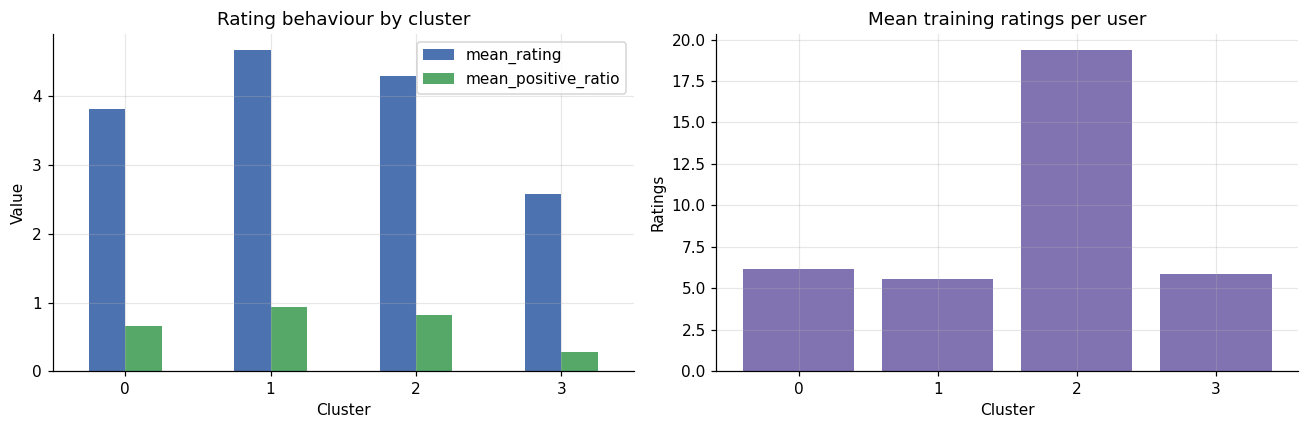

In [21]:
# Attach full-population KMeans labels to original training-only user summaries.
user_profiles = user_features.copy()
user_profiles["cluster"] = kmeans_labels
# Summarize size, activity, rating level and positive/negative behaviour per cluster.
cluster_profile = user_profiles.groupby("cluster").agg(
    users=("rating_count", "size"),
    mean_rating_count=("rating_count", "mean"),
    median_rating_count=("rating_count", "median"),
    mean_rating=("mean_rating", "mean"),
    mean_rating_std=("rating_std", "mean"),
    mean_positive_ratio=("positive_ratio", "mean"),
    mean_negative_ratio=("negative_ratio", "mean"),
)
# Show cluster size as a share of the eligible-user population.
cluster_profile["% of users"] = 100 * cluster_profile["users"] / len(user_profiles)

# Use the overall training-user activity mean to distinguish higher from lower activity.
overall_activity = user_profiles["rating_count"].mean()
cluster_labels = []
# Assign readable labels from behavioural statistics, not from cluster numbers alone.
for _, row in cluster_profile.iterrows():
    # Compare each cluster's average history length with the population average.
    if row["mean_rating_count"] > overall_activity:
        activity = "higher-activity"
    else:
        activity = "lower-activity"

    # Label more critical users first when at least 40% of ratings are 1–2 stars.
    if row["mean_negative_ratio"] >= 0.40:
        rating_style = "more critical raters"
    # Otherwise identify clusters where at least 80% of ratings are positive.
    elif row["mean_positive_ratio"] >= 0.80:
        rating_style = "positive raters"
    else:
        rating_style = "mixed raters"

    cluster_labels.append(f"{activity} / {rating_style}")

# Attach the descriptive labels to the profile table for charts and candidate summaries.
cluster_profile["label"] = cluster_labels
display(cluster_profile.style.format({"users": "{:,}", "mean_rating_count": "{:.2f}",
                                      "median_rating_count": "{:.1f}", "mean_rating": "{:.3f}",
                                      "mean_rating_std": "{:.3f}", "mean_positive_ratio": "{:.3f}",
                                      "mean_negative_ratio": "{:.3f}", "% of users": "{:.2f}%"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cluster_profile[["mean_rating", "mean_positive_ratio"]].plot(kind="bar", ax=axes[0], color=["#4C72B0", "#55A868"])
axes[0].set(title="Rating behaviour by cluster", xlabel="Cluster", ylabel="Value")
axes[0].tick_params(axis="x", rotation=0)
axes[1].bar(cluster_profile.index.astype(str), cluster_profile["mean_rating_count"], color="#8172B2")
axes[1].set(title="Mean training ratings per user", xlabel="Cluster", ylabel="Ratings")
finish_chart(fig)

**Observation:** Cluster 0 is lower-activity / mixed raters; Cluster 1 is lower-activity / positive raters; Cluster 2 is higher-activity / positive raters; Cluster 3 is lower-activity / more critical raters. These short labels summarize the measured profiles and should not be read as fixed user types.

## 14. SVD-based Clustering Approach

The user-product matrix is extremely sparse, so CSR stores only observed training ratings instead of allocating a dense matrix. TruncatedSVD turns those interactions into 50-dimensional user embeddings; 50 components are a practical compact representation for this comparison, not a theoretically optimal choice. The embeddings are L2-normalized before comparing k values, and the notebook selects k=6 using its summed metric-rank rule with smaller-k tie breaking. The roughly 4.77% cumulative explained variance is a diagnostic of this sparse decomposition, not a dense-PCA-style target for variance captured.

In [22]:
# Map string IDs to codes; store only observed ratings in the sparse matrix.
# Keep a string ID for every SVD matrix row so latent labels map back to users.
user_ids_svd = user_features.index.astype(str).to_numpy()
# Create a compact lookup from categorical user code to matrix row; -1 marks missing mappings.
user_row_by_code = np.full(len(train_df["userId"].cat.categories), -1, dtype=np.int32)
# Place each training user's profile row at the position of its categorical code.
user_row_by_code[user_features.index.codes] = np.arange(len(user_features), dtype=np.int32)
# Convert each training interaction's user ID to its compact integer code.
train_user_codes = train_df["userId"].cat.codes.to_numpy()
# Map every training interaction to the corresponding user matrix row.
matrix_rows = user_row_by_code[train_user_codes]

# Get compact codes for the products in the training interactions.
train_product_codes = train_df["productId"].cat.codes.to_numpy()
# Retain only products observed in training and sort their category codes.
svd_product_codes = np.unique(train_product_codes)
# Translate possibly sparse category codes into consecutive matrix columns.
matrix_cols = np.searchsorted(svd_product_codes, train_product_codes)
# Keep the matching string product IDs to interpret matrix columns later.
product_ids_svd = train_df["productId"].cat.categories[svd_product_codes].astype(str).to_numpy()

# Create a CSR matrix containing only observed training ratings; a dense matrix would be impractical.
svd_matrix = csr_matrix(
    (train_df["Rating"].to_numpy(dtype=np.float32), (matrix_rows, matrix_cols)),
    shape=(len(user_ids_svd), len(product_ids_svd)), dtype=np.float32,
)
# Check that every training row maps to a valid user profile.
assert (matrix_rows >= 0).all()
# Check that all unique training interactions appear as sparse entries.
assert svd_matrix.nnz == len(train_df)
# Keep the SVD row-to-user mapping aligned with the feature table.
assert len(user_ids_svd) == len(user_features)

# Measure SVD fit time separately from matrix construction.
svd_started = time.perf_counter()
# Learn latent user embeddings from training ratings only.
# Use 50 components as a practical compact comparison, not as a theoretically optimal dimension.
svd_model = TruncatedSVD(n_components=50, random_state=RANDOM_STATE)
svd_raw_embeddings = svd_model.fit_transform(svd_matrix)
# L2-normalize vectors so KMeans emphasizes preference direction rather than embedding magnitude.
svd_embeddings = normalize(svd_raw_embeddings, norm="l2")
svd_seconds = time.perf_counter() - svd_started
# Report matrix size, stored interactions, component count, variance diagnostic and runtime.
svd_summary = pd.DataFrame([{
    "sparse matrix shape": str(svd_matrix.shape),
    "training non-zeros": int(svd_matrix.nnz),
    "SVD components": svd_model.n_components,
    "cumulative explained variance": svd_model.explained_variance_ratio_.sum(),
    "SVD runtime (seconds)": svd_seconds,
}])
display(svd_summary.style.format({"training non-zeros": "{:,}",
                                  "cumulative explained variance": "{:.4f}",
                                  "SVD runtime (seconds)": "{:.1f}"}).hide(axis="index"))
print("Explained variance is a sparse-matrix decomposition diagnostic, not dense-PCA variance.")
print(f"Normalized user embedding shape: {svd_embeddings.shape}.")

sparse matrix shape,training non-zeros,SVD components,cumulative explained variance,SVD runtime (seconds)
"(254064, 269849)","2,028,405",50,0.0477,21.5


Explained variance is a sparse-matrix decomposition diagnostic, not dense-PCA variance.
Normalized user embedding shape: (254064, 50).


In [23]:
# Select k on the shared sample, then fit the selected model on all users.
# Reuse Approach A's sampled user positions for a fair representation comparison.
svd_metric_sample = svd_embeddings[metric_sample]
svd_k_rows = []
# Evaluate SVD clustering candidates over the same k range as behavioural KMeans.
for k in range(2, 9):
    sample_model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    # Fit on the shared sample and collect its cluster assignment in one step.
    sample_labels = sample_model.fit_predict(svd_metric_sample)
    svd_k_rows.append({
        "k": k,
        # Measure within-cluster compactness on the sample; lower inertia alone does not select k.
        "inertia (10k sample)": sample_model.inertia_,
        "silhouette (10k sample)": silhouette_score(svd_metric_sample, sample_labels),
        "davies-bouldin (10k sample)": davies_bouldin_score(svd_metric_sample, sample_labels),
        "calinski-harabasz (10k sample)": calinski_harabasz_score(svd_metric_sample, sample_labels),
    })
svd_k_table = pd.DataFrame(svd_k_rows)
# Rank the three separation metrics in their preferred directions and add the ranks.
svd_k_table["metric rank sum"] = (
    svd_k_table["silhouette (10k sample)"].rank(ascending=False, method="min")
    + svd_k_table["davies-bouldin (10k sample)"].rank(ascending=True, method="min")
    + svd_k_table["calinski-harabasz (10k sample)"].rank(ascending=False, method="min")
)
# Choose the lowest total rank; sorting by k makes the smaller k win a tie.
SVD_K_SELECTED = int(svd_k_table.sort_values(["metric rank sum", "k"]).iloc[0]["k"])
display(svd_k_table.style.format({
    "inertia (10k sample)": "{:,.0f}",
    "silhouette (10k sample)": "{:.4f}",
    "davies-bouldin (10k sample)": "{:.4f}",
    "calinski-harabasz (10k sample)": "{:,.0f}",
    "metric rank sum": "{:.0f}",
}).hide(axis="index"))
print(f"Selected k={SVD_K_SELECTED} by summed ranks of Silhouette, Davies-Bouldin and Calinski-Harabasz; smaller k breaks ties.")

# Fit the selected SVD KMeans model on all eligible user embeddings.
svd_kmeans = KMeans(n_clusters=SVD_K_SELECTED, random_state=RANDOM_STATE, n_init=10)
svd_cluster_labels = svd_kmeans.fit_predict(svd_embeddings)
# Interpret latent clusters with original behaviour features rather than assigning meanings to SVD components.
svd_profiles = user_features.copy()
svd_profiles["cluster"] = svd_cluster_labels
svd_cluster_profile = svd_profiles.groupby("cluster").agg(
    users=("rating_count", "size"),
    mean_rating_count=("rating_count", "mean"),
    median_rating_count=("rating_count", "median"),
    mean_rating=("mean_rating", "mean"),
    positive_ratio=("positive_ratio", "mean"),
    negative_ratio=("negative_ratio", "mean"),
)
# Check both cluster sizes and whether one group dominates the population.
svd_cluster_profile["% of users"] = 100 * svd_cluster_profile["users"] / len(svd_profiles)
display(svd_cluster_profile.style.format({
    "users": "{:,}", "mean_rating_count": "{:.2f}", "median_rating_count": "{:.1f}",
    "mean_rating": "{:.3f}", "positive_ratio": "{:.3f}", "negative_ratio": "{:.3f}",
    "% of users": "{:.2f}%",
}))
print(f"Final SVD K-Means fitted on {len(svd_cluster_labels):,} users; largest cluster share: {svd_cluster_profile['% of users'].max():.2f}%.")

k,inertia (10k sample),silhouette (10k sample),davies-bouldin (10k sample),calinski-harabasz (10k sample),metric rank sum
2,"7,383",0.0787,3.7143,715,10
3,"6,993",0.0570,3.3157,656,15
4,"6,640",0.0680,2.9708,637,13
5,"6,401",0.0679,2.8352,589,14
6,"6,274",0.0772,2.6319,521,9
7,"6,129",0.0801,2.6572,484,9
8,"6,023",0.0728,2.7085,447,14


Selected k=6 by summed ranks of Silhouette, Davies-Bouldin and Calinski-Harabasz; smaller k breaks ties.


,users,mean_rating_count,median_rating_count,mean_rating,positive_ratio,negative_ratio,% of users
cluster,,,,,,,
0,"39,833",6.77,5.0,3.997,0.726,0.168,15.68%
1,"70,284",9.17,6.0,4.179,0.782,0.128,27.66%
2,"32,821",8.94,5.0,3.907,0.704,0.185,12.92%
3,"23,580",8.27,6.0,4.129,0.768,0.133,9.28%
4,"31,589",7.54,6.0,4.106,0.759,0.147,12.43%
5,"55,957",6.93,5.0,4.035,0.738,0.160,22.02%


Final SVD K-Means fitted on 254,064 users; largest cluster share: 27.66%.


**Observation:** The 50-component representation has about 4.77% cumulative explained variance; here this is a sparse-decomposition diagnostic, not a PCA-like variance target. The selected SVD model uses k=6 and its clusters are interpreted with the original behavioural summaries.

## 15. Cluster-Based Recommendation System

For a known user, the system selects their cluster and aggregates product ratings from that cluster's training interactions. Candidates require support ≥10, mean rating ≥4.0, and positive share ≥60%; these safeguards prevent a few ratings from making an item appear reliable. After filtering, products are ordered by positive count, then mean rating, then total support: positive evidence leads, while a high average from thin support cannot enter the list. Each stored candidate list is capped to bound scanning, previously rated products are skipped, and unsupported users use Global Popularity fallback.

In [24]:
# Map categorical user codes directly.  This avoids a costly categorical-index join.
# Convert categorical user IDs to compact integers for fast per-row label lookup.
user_codes = train_df["userId"].cat.codes.to_numpy()
# Keep matching product codes for the seen-item histories built below.
product_codes = train_df["productId"].cat.codes.to_numpy()
# Reserve one small slot per user category; -1 marks a user without an assigned cluster.
cluster_by_user_code = np.full(len(train_df["userId"].cat.categories), -1, dtype=np.int8)
# Place each KMeans label at the slot for that user's category code.
cluster_by_user_code[user_profiles.index.codes] = kmeans_labels.astype("int8")
# Start recommendation statistics from training rows only.
train_labelled = train_df[["userId", "productId", "Rating"]].copy()
train_labelled["cluster"] = cluster_by_user_code[user_codes]
# Ensure every modelling interaction is attached to an eligible user's KMeans cluster.
assert (train_labelled["cluster"] >= 0).all()
# Count 4–5 star interactions as positive preference for candidate filters.
train_labelled["is_positive"] = (train_labelled["Rating"] >= 4).astype("int8")
# Aggregate support, average rating and positive count for each cluster-product pair.
cluster_products = (train_labelled.groupby(["cluster", "productId"], observed=True)
                    .agg(cluster_rating_count=("Rating", "size"),
                         cluster_mean_rating=("Rating", "mean"),
                         cluster_positive_count=("is_positive", "sum"))
                    .reset_index())
cluster_products["cluster_positive_rate"] = (
    cluster_products["cluster_positive_count"] / cluster_products["cluster_rating_count"]
)

# Apply the same quality filters and ranking rules to both clusters and global popularity.
def rank_candidates(stats, group_col):
    """Filter and rank product statistics for each group.

    Args:
        stats: Training-only support, mean and positive-count table.
        group_col: Column identifying a cluster or the global list.
    Returns:
        Filtered candidate statistics and capped ranked product-ID lists.
    """
    # Keep supported products that meet the positive-preference safeguards.
    candidates = stats[
        (stats["cluster_rating_count"] >= MIN_SUPPORT)
        & (stats["cluster_mean_rating"] >= MIN_CLUSTER_MEAN_RATING)
        & (stats["cluster_positive_rate"] >= MIN_CLUSTER_POSITIVE_RATE)
    ].copy()
    # Minimum support blocks thin evidence; positive count ranks first, then mean rating, then support.
    candidates = candidates.sort_values(
        [group_col, "cluster_positive_count", "cluster_mean_rating", "cluster_rating_count"],
        ascending=[True, False, False, False],
    )
    ranked_lists = {}
    for group_value, group_data in candidates.groupby(group_col, observed=True):
        ranked_lists[group_value] = group_data["productId"].astype(str).head(CANDIDATE_POOL).tolist()
    return candidates, ranked_lists

# Build each cluster's ranked candidates and capped list for user-level filtering.
rankable_cluster_products, cluster_lists = rank_candidates(cluster_products, "cluster")
# Report eligible products before the per-list cap so small pools are visible.
candidate_summary = (rankable_cluster_products.groupby("cluster", observed=True).size()
                     .rename("eligible products").to_frame().join(cluster_profile["label"]))
display(candidate_summary[["label", "eligible products"]])
print(f"Candidate list cap: {CANDIDATE_POOL:,}; eligibility counts above are uncapped.")

# Build seen histories from compact categorical codes, then use code lookups at ranking time.
# This avoids the very slow per-group Series-to-set conversion on 250k users.
# Store each user's rated products as integer codes to make exclusions compact.
seen_product_codes = {}
# Build one seen-item set from training interactions; held-out products are absent.
for user_code, product_code in zip(user_codes, product_codes):
    seen_product_codes.setdefault(int(user_code), set()).add(int(product_code))
# Translate entered string user IDs back to their categorical codes.
user_code_lookup = {str(user_id): code for code, user_id in
                    enumerate(train_df["userId"].cat.categories)}
# Translate candidate product IDs to codes for fast membership tests.
product_code_lookup = {str(product_id): code for code, product_id in
                       enumerate(train_df["productId"].cat.categories)}
# Release large temporary arrays after the dictionaries are built.
del user_codes, product_codes
# Map each known string user ID to the cluster used for recommendations.
user_cluster_map = {str(user_id): int(cluster) for user_id, cluster in user_profiles["cluster"].items()}
# Keep per-cluster product statistics indexed by string product ID for display.
cluster_lookup = {int(cluster): group.set_index(group["productId"].astype(str))
                  for cluster, group in rankable_cluster_products.groupby("cluster", observed=True)}

,label,eligible products
cluster,,
0,lower-activity / mixed raters,4035
1,lower-activity / positive raters,9837
2,higher-activity / positive raters,12251
3,lower-activity / more critical raters,47


Candidate list cap: 1,000; eligibility counts above are uncapped.


In [25]:
# Return up to n ranked products for one user after removing training-seen items.
def top_n_for_user(user_id, ranked_lists, group_for_user, n=TOP_N):
    """Return the first n unseen products from the user's ranked group.

    Args:
        user_id: User ID, matched as a string.
        ranked_lists: Group-to-ranked-product mapping.
        group_for_user: User-to-cluster or user-to-global-list mapping.
        n: Maximum number of products to return.
    Returns:
        An ordered list of unseen product IDs.
    """
    user_id = str(user_id)
    # Select the list for this user's cluster, or an empty list when no group is known.
    pool = ranked_lists.get(group_for_user.get(user_id), [])
    # Fetch the user's training history; unknown users have no known seen set.
    seen = seen_product_codes.get(user_code_lookup.get(user_id), set())
    recs = []
    # Exclude products already rated by this user.
    # Scan in ranking order and stop as soon as the requested number of unseen products is collected.
    for product in pool:
        if product_code_lookup[product] not in seen:
            recs.append(product)
            if len(recs) == n:
                break
    # Return product IDs only; the order remains the candidate ranking order.
    return recs


# Return a display table with rank and training-only cluster statistics for a known user.
def recommend_products(user_id, n=TOP_N):
    """Build a display table of recommendations for a known Approach A user.

    Args:
        user_id: User ID used to look up the training cluster.
        n: Maximum number of products to return.
    Returns:
        A DataFrame with rank, product ID and cluster training statistics; empty if unsupported.
    """
    user_id = str(user_id)
    # Look up the cluster assigned from the user's training-only behavioural profile.
    cluster = user_cluster_map.get(user_id)
    columns = ["productId", "cluster_rating_count", "cluster_mean_rating",
               "cluster_positive_count", "cluster_positive_rate"]
    picks = top_n_for_user(user_id, cluster_lists, user_cluster_map, n)
    # Return an empty, correctly shaped table if the notebook helper cannot produce recommendations.
    if cluster is None or not picks:
        return pd.DataFrame(columns=["rank", *columns])
    # Retrieve statistics in the same order as the ranked product IDs.
    out = cluster_lookup[cluster].loc[picks, columns[1:]].reset_index()
    out.insert(0, "rank", range(1, len(out) + 1))
    return out


# Prepare one stable example user from each cluster to inspect the lists.
example_users = user_profiles.copy()
example_users["example_user_id"] = example_users.index.astype(str)
example_users = example_users.sort_values("example_user_id")
# Use the first sorted ID per cluster so examples are reproducible.
examples = example_users.groupby("cluster", observed=True).first()
for cluster, row in examples.iterrows():
    print(f"Cluster {cluster}: {cluster_profile.loc[cluster, 'label']}")
    display(recommend_products(row["example_user_id"], n=5))

Cluster 0: lower-activity / mixed raters


,rank,productId,cluster_rating_count,cluster_mean_rating,cluster_positive_count,cluster_positive_rate
0,1,B007WTAJTO,1053,4.218424,839,0.796771
1,2,B003ES5ZUU,776,4.692010,717,0.923969
2,3,B0019EHU8G,786,4.637405,709,0.902036
3,4,B003ELYQGG,753,4.108898,555,0.737052
4,5,B009SYZ8OC,637,4.153846,481,0.755102


Cluster 1: lower-activity / positive raters


,rank,productId,cluster_rating_count,cluster_mean_rating,cluster_positive_count,cluster_positive_rate
0,1,B007WTAJTO,1643,4.869142,1618,0.984784
1,2,B003ES5ZUU,1441,4.867453,1425,0.988897
2,3,B0019EHU8G,1275,4.901961,1264,0.991373
3,4,B002WE6D44,1103,4.870354,1089,0.987307
4,5,B00DR0PDNE,1093,4.598353,994,0.909424


Cluster 2: higher-activity / positive raters


,rank,productId,cluster_rating_count,cluster_mean_rating,cluster_positive_count,cluster_positive_rate
0,1,B007WTAJTO,1832,4.667031,1697,0.926310
1,2,B003ES5ZUU,1553,4.832582,1515,0.975531
2,3,B0019EHU8G,1101,4.842870,1068,0.970027
3,4,B002WE6D44,1023,4.683284,954,0.932551
4,5,B002V88HFE,903,4.766334,860,0.952381


Cluster 3: lower-activity / more critical raters


,rank,productId,cluster_rating_count,cluster_mean_rating,cluster_positive_count,cluster_positive_rate
0,1,B003ZUIHY8,61,4.000000,39,0.639344
1,2,B0052SCU8U,33,4.212121,26,0.787879
2,3,B001E1Y5O6,31,4.451613,25,0.806452
3,4,B003Z4G3I6,26,4.423077,24,0.923077
4,5,B002ZIMEMW,24,4.125000,19,0.791667


**Observation:** Candidate counts differ by cluster, reflecting the support and preference filters; the more critical segment has the smaller eligible pool. Example lists are ranked training-only candidates after previously rated products are excluded.

In [26]:
# Reserve a cluster slot for each categorical user; -1 marks any unassigned category.
svd_cluster_by_user_code = np.full(len(train_df["userId"].cat.categories), -1, dtype=np.int8)
# Map Approach B's final SVD KMeans labels back to user codes.
svd_cluster_by_user_code[user_features.index.codes] = svd_cluster_labels.astype(np.int8)
# Build Approach B's product statistics from the same training interactions as Approach A.
svd_train_labelled = train_df[["userId", "productId", "Rating"]].copy()
svd_train_labelled["cluster"] = svd_cluster_by_user_code[train_df["userId"].cat.codes.to_numpy()]
# Check that every modelling interaction has an SVD cluster assignment.
assert (svd_train_labelled["cluster"] >= 0).all()
svd_train_labelled["is_positive"] = (svd_train_labelled["Rating"] >= 4).astype("int8")

# Aggregate support, mean rating and positive count for each SVD cluster-product pair.
svd_cluster_products = (svd_train_labelled.groupby(["cluster", "productId"], observed=True)
                        .agg(cluster_rating_count=("Rating", "size"),
                             cluster_mean_rating=("Rating", "mean"),
                             cluster_positive_count=("is_positive", "sum"))
                        .reset_index())
svd_cluster_products["cluster_positive_rate"] = (
    svd_cluster_products["cluster_positive_count"] / svd_cluster_products["cluster_rating_count"]
)
# Reuse the identical support, preference and ranking rules from Approach A.
svd_rankable_products, svd_cluster_lists = rank_candidates(svd_cluster_products, "cluster")
# Show eligible SVD-cluster product counts before the candidate-pool cap.
svd_candidate_summary = (svd_rankable_products.groupby("cluster", observed=True).size()
                         .rename("eligible products").to_frame())
display(svd_candidate_summary)

# Map the same string user IDs to their final SVD cluster labels.
svd_user_cluster_map = dict(zip(user_ids_svd, svd_cluster_labels.astype(int)))

,eligible products
cluster,
0,2473
1,7851
2,3318
3,2187
4,2619
5,4281


**Observation:** Approach B applies the same support/preference ranking rules and candidate cap using SVD cluster assignments. Both representations are evaluated on the shared holdout rather than creating a second test split.

## 16. Recommendation Evaluation

Hit Rate@10 is the share of users whose held-out positive item appears in the Top 10; with one target per user, Recall@10 has the same value. For each user, Precision@10 is 1/10 when that single target is hit and zero otherwise, so the aggregate is Hit Rate@10 divided by ten. User coverage is the share receiving at least one item, full Top-10 coverage is the share receiving all ten, and catalog coverage is the share of training products recommended. Warm-item metrics use targets present in training; overall positive-holdout Hit Rate includes every target and counts cold products as misses. All approaches use the same held-out targets and warm users for a fair comparison.

In [27]:
# Use the same warm positive targets for each recommendation approach.
# Create one common truth item per warm user so all methods face the same test targets.
held_out = warm_test_df.assign(userId=warm_test_df["userId"].astype(str)).set_index("userId")["productId"].astype(str)
# Protect the single-positive-target-per-user evaluation design.
assert held_out.index.is_unique


# Apply the same Top-N evaluation calculations to every recommendation list.
def evaluate_recommender(ranked_lists, group_for_user, label, n=TOP_N):
    """Measure Top-N quality and coverage on the shared warm holdout.

    Args:
        ranked_lists: Group-to-ranked-product mapping being tested.
        group_for_user: User-to-group mapping for this approach.
        label: Display name for the result row.
        n: Recommendation-list length.
    Returns:
        A metrics dictionary; cold targets remain misses in the overall hit rate.
    """
    # A hit is counted when the user's held-out positive product appears in their top n results.
    hits = 0
    rec_counts = []
    recommended_products = set()
    # Evaluate every warm user's one known positive target against their recommendations.
    for user_id, truth in held_out.items():
        recs = top_n_for_user(user_id, ranked_lists, group_for_user, n)
        rec_counts.append(len(recs))
        recommended_products.update(recs)
        # Add one hit only when the target product is present in the returned list.
        hits += int(truth in recs)
    evaluated = len(held_out)
    return {
        "approach": label,
        "evaluated warm users": evaluated,
        "hits": hits,
        # Hit Rate is the fraction of evaluated users whose positive target was found.
        "Hit Rate@10": hits / evaluated,
        # With one relevant item per user and a fixed top-10 denominator, Precision equals Hit Rate divided by 10.
        "Precision@10": hits / evaluated / n,
        # Recall equals Hit Rate here because each user has exactly one held-out relevant item.
        "Recall@10": hits / evaluated,
        # User coverage is the share receiving at least one recommendation.
        "user coverage %": 100 * np.mean(np.asarray(rec_counts) >= 1),
        # Full-list coverage is the share receiving all n recommendations.
        "full Top-10 coverage %": 100 * np.mean(np.asarray(rec_counts) == n),
        "distinct recommended products": len(recommended_products),
        # Catalog coverage is the distinct recommended products divided by the training catalogue.
        "catalog coverage %": 100 * len(recommended_products) / len(train_catalogue),
        # The all-target denominator includes cold-item users, so cold targets count as misses.
        "Overall Positive-Holdout Hit Rate@10": hits / len(test_df),
    }


# Score Approach A on the warm users, then show warm and overall availability separately.
cluster_result = evaluate_recommender(
    cluster_lists, user_cluster_map, "Approach A: Behavioural User Clustering"
)
approach_a_result = cluster_result.copy()
availability = pd.DataFrame([
    ("Positive hold-outs", len(test_df), 100.0),
    ("Warm held-out positives", len(warm_test_df), 100 * len(warm_test_df) / len(test_df)),
    ("Cold held-out positives", len(cold_test_df), 100 * len(cold_test_df) / len(test_df)),
], columns=["case", "users", "% of positive hold-outs"])
display(availability.style.format({
    "users": "{:,}", "% of positive hold-outs": "{:.3f}%"
}).hide(axis="index"))
display(pd.DataFrame([cluster_result]).set_index("approach").T)

# Recheck no training interaction overlaps the evaluation holdout.
assert train_df.index.intersection(test_df.index).empty
# Recheck the test targets are all positive ratings.
assert (test_df["Rating"] >= 4).all()
# Confirm the warm evaluator contains only products available in training.
assert set(held_out.values).issubset(train_catalogue)
# Confirm cold targets are absent and therefore overall misses.
assert set(cold_test_df["productId"].astype(str)).isdisjoint(train_catalogue)
print("Approach A uses training-only profiles and ranking; cold items count as overall misses.")

case,users,% of positive hold-outs
Positive hold-outs,"252,723",100.000%
Warm held-out positives,"237,187",93.853%
Cold held-out positives,"15,536",6.147%


approach,Approach A: Behavioural User Clustering
evaluated warm users,237187.000000
hits,4301.000000
Hit Rate@10,0.018133
Precision@10,0.001813
Recall@10,0.018133
user coverage %,100.000000
full Top-10 coverage %,100.000000
distinct recommended products,31.000000
catalog coverage %,0.011488
Overall Positive-Holdout Hit Rate@10,0.017019


Approach A uses training-only profiles and ranking; cold items count as overall misses.


In [28]:
# Aggregate global product support and preference from training data only.
global_products = (train_labelled.groupby("productId", observed=True)
                   .agg(cluster_rating_count=("Rating", "size"),
                        cluster_mean_rating=("Rating", "mean"),
                        cluster_positive_count=("is_positive", "sum"))
                   .reset_index())
global_products["cluster_positive_rate"] = (
    global_products["cluster_positive_count"] / global_products["cluster_rating_count"]
)
# Use a single group key so the shared ranking helper builds one global list.
global_products["group"] = 0
_, global_lists = rank_candidates(global_products, "group")
# Assign every warm evaluation user to the same global list for a fair baseline.
global_group_map = {user_id: 0 for user_id in held_out.index}
# Evaluate popularity on exactly the same warm targets and top-10 rule.
baseline_result = evaluate_recommender(global_lists, global_group_map, "Global Popularity Baseline")
popularity_result = baseline_result.copy()
display(pd.DataFrame([cluster_result, baseline_result]).set_index("approach").T)

# Evaluate SVD-cluster lists with the same function, users and held-out products.
approach_b_result = evaluate_recommender(
    svd_cluster_lists, svd_user_cluster_map, "Approach B: SVD Interaction-Based User Clustering"
)
# Check Approach B preserves the exact Approach A evaluation-user order.
assert held_out.index.equals(pd.Index(warm_test_df["userId"].astype(str), name="userId"))
assert len(held_out) == len(warm_test_df)
# Check every SVD-labelled user has a recommendation cluster mapping.
assert set(svd_user_cluster_map) == set(user_ids_svd)
display(pd.DataFrame([approach_b_result]).set_index("approach").T)
print("Approach B uses the same warm held-out users and positive-item test split as Approach A.")

approach,Approach A: Behavioural User Clustering,Global Popularity Baseline
evaluated warm users,237187.000000,237187.000000
hits,4301.000000,4413.000000
Hit Rate@10,0.018133,0.018606
Precision@10,0.001813,0.001861
Recall@10,0.018133,0.018606
user coverage %,100.000000,100.000000
full Top-10 coverage %,100.000000,100.000000
distinct recommended products,31.000000,18.000000
catalog coverage %,0.011488,0.006670
Overall Positive-Holdout Hit Rate@10,0.017019,0.017462


approach,Approach B: SVD Interaction-Based User Clustering
evaluated warm users,237187.000000
hits,3214.000000
Hit Rate@10,0.013550
Precision@10,0.001355
Recall@10,0.013550
user coverage %,100.000000
full Top-10 coverage %,100.000000
distinct recommended products,99.000000
catalog coverage %,0.036687
Overall Positive-Holdout Hit Rate@10,0.012717


Approach B uses the same warm held-out users and positive-item test split as Approach A.


**Observation:** Warm results measure recommendation quality only where the held-out product exists in training; overall Hit Rate also includes the 15,536 cold targets as misses. Using identical users and targets keeps the popularity benchmark comparable to both clustering approaches.

## 17. Model Comparison and Final Selection

The comparison reports warm recommendation quality and coverage for both clustering representations and the Global Popularity benchmark. Popularity remains the performance benchmark and fallback; the selected deployment is a clustering model to satisfy the project's clustering-deployment requirement.

In [29]:
# Format one method's metrics consistently for the final side-by-side table.
def comparison_row(name, result, clusters):
    """Select and label the shared metrics for one comparison row.

    Args:
        name: Method label shown in the table.
        result: Metrics returned by evaluate_recommender.
        clusters: Selected cluster count, or a dash for the baseline.
    Returns:
        A flat dictionary ready to add to the comparison DataFrame.
    """
    return {
        "approach": name,
        "clusters": clusters,
        "Hit Rate@10 (warm)": result["Hit Rate@10"],
        "Precision@10": result["Precision@10"],
        "Recall@10": result["Recall@10"],
        "user coverage": result["user coverage %"] / 100,
        "full Top-10 coverage": result["full Top-10 coverage %"] / 100,
        "catalog coverage": result["catalog coverage %"] / 100,
        "overall positive-holdout Hit Rate@10": result["Overall Positive-Holdout Hit Rate@10"],
        "distinct recommended products": result["distinct recommended products"],
    }

# Place the two clustering representations beside the global popularity benchmark.
comparison = pd.DataFrame([
    comparison_row("Approach A: Behavioural User Clustering", approach_a_result, K_SELECTED),
    comparison_row("Approach B: SVD Interaction-Based User Clustering", approach_b_result, SVD_K_SELECTED),
    comparison_row("Global Popularity Baseline (benchmark)", popularity_result, "—"),
])
display(comparison.style.format({
    "Hit Rate@10 (warm)": "{:.2%}", "Precision@10": "{:.2%}", "Recall@10": "{:.2%}",
    "user coverage": "{:.2%}", "full Top-10 coverage": "{:.2%}", "catalog coverage": "{:.4%}",
    "overall positive-holdout Hit Rate@10": "{:.2%}",
    "distinct recommended products": "{:,}",
}).hide(axis="index"))

# Popularity is the benchmark; the selected deployment must still be a clustering model under the project requirement.
# The project acceptance criterion requires a clustering-based deployment model.
selected_model = "Approach A: Behavioural User Clustering using KMeans, k=4"
# Keep the selected clustering model's metrics available as the deployment summary.
selected_result = approach_a_result

print("Final Model Selection")
print(f"Selected clustering-based recommendation model for deployment: {selected_model}")
print(f"Approach A warm Hit Rate@10: {approach_a_result['Hit Rate@10']:.4%}; "
      f"Precision@10: {approach_a_result['Precision@10']:.4%}; "
      f"Recall@10: {approach_a_result['Recall@10']:.4%}.")
print(f"Global Popularity benchmark warm Hit Rate@10: {popularity_result['Hit Rate@10']:.4%}.")
# Express the popularity-vs-Approach-A difference in percentage points, not as a significance claim.
benchmark_advantage_pp = (popularity_result["Hit Rate@10"] - approach_a_result["Hit Rate@10"]) * 100
print(f"The benchmark's observed advantage is about {benchmark_advantage_pp:.4f} percentage points; "
      "no statistical significance test was performed, so this is not evidence of meaningful superiority.")
print(f"Approach A catalog coverage: {approach_a_result['catalog coverage %']:.4f}%, "
      f"above the popularity benchmark at {popularity_result['catalog coverage %']:.4f}%; "
      "it retains user segments and cluster-based recommendations for the clustering-deployment requirement.")
print(f"Approach B catalog coverage is higher ({approach_b_result['catalog coverage %']:.4f}%), "
      f"but its warm Hit Rate@10 is lower ({approach_b_result['Hit Rate@10']:.4%} vs "
      f"{approach_a_result['Hit Rate@10']:.4%}) and SVD adds complexity; it is not selected.")
print("Global Popularity remains the benchmark, not the selected clustering model.")
print("Approach A has been deployed as the Streamlit clustering-based recommendation application.")

approach,clusters,Hit Rate@10 (warm),Precision@10,Recall@10,user coverage,full Top-10 coverage,catalog coverage,overall positive-holdout Hit Rate@10,distinct recommended products
Approach A: Behavioural User Clustering,4,1.81%,0.18%,1.81%,100.00%,100.00%,0.0115%,1.70%,31
Approach B: SVD Interaction-Based User Clustering,6,1.36%,0.14%,1.36%,100.00%,100.00%,0.0367%,1.27%,99
Global Popularity Baseline (benchmark),—,1.86%,0.19%,1.86%,100.00%,100.00%,0.0067%,1.75%,18


Final Model Selection
Selected clustering-based recommendation model for deployment: Approach A: Behavioural User Clustering using KMeans, k=4
Approach A warm Hit Rate@10: 1.8133%; Precision@10: 0.1813%; Recall@10: 1.8133%.
Global Popularity benchmark warm Hit Rate@10: 1.8606%.
The benchmark's observed advantage is about 0.0472 percentage points; no statistical significance test was performed, so this is not evidence of meaningful superiority.
Approach A catalog coverage: 0.0115%, above the popularity benchmark at 0.0067%; it retains user segments and cluster-based recommendations for the clustering-deployment requirement.
Approach B catalog coverage is higher (0.0367%), but its warm Hit Rate@10 is lower (1.3550% vs 1.8133%) and SVD adds complexity; it is not selected.
Global Popularity remains the benchmark, not the selected clustering model.
Approach A has been deployed as the Streamlit clustering-based recommendation application.


**Interpretation:** Global Popularity has the highest observed warm Hit Rate@10 (1.8606%), versus 1.8133% for Behavioural KMeans and 1.3550% for SVD + KMeans. Its margin over Behavioural KMeans is about 0.0472 percentage points; no significance test was run, so this does not establish meaningful superiority or statistical equivalence. SVD + KMeans has higher catalog coverage (0.0367%) than Behavioural KMeans (0.0115%) and popularity (0.0067%), but lower hit rate and added complexity. Behavioural KMeans, k=4, is selected as the deployed clustering model for interpretable segments, close observed benchmark performance, simpler serving than SVD, and direct fit with the clustering-deployment requirement; Global Popularity remains the benchmark and fallback.

## 18. Deployment Summary

The Streamlit app serves precomputed artifacts, so it neither loads `ratings.csv` nor retrains at runtime. Known modelled users receive saved cluster recommendations with previously rated products excluded; unsupported users receive Global Popularity fallback. The source has product IDs but no names, so the app displays IDs only.

**Selected model:** Behavioural User Clustering using KMeans, k=4 · **Platform:** Streamlit Community Cloud

**Live URL:** [P704 Recommendation System](https://p704-recommendation-system.streamlit.app/)

**Challenges and solutions**

| Challenge | Solution |
|---|---|
| 7.8M-row dataset | Chunked file checks and temporary SQLite aggregation. |
| Extreme sparsity | Sparse interactions; no dense user-product matrix. |
| Memory usage | 250,000-row chunks; largest observed chunk was 55.49 MiB. |
| Large raw CSV | Keep it in local/Drive analysis storage; deploy compact artifacts only. |
| Unsupported/cold users | Popularity fallback for unsupported users; cold products count as overall misses. |
| Seen products | Sparse training history excludes rated items; optional IDs can be supplied for unsupported users. |
| Product names unavailable | Display product IDs only; do not infer names. |

### Deployment Model Artifacts

The already-fitted Approach A scaler and k=4 KMeans model are serialized for future onboarding, allowing a new user's five behavioural features to be transformed and assigned to an existing cluster without retraining. The five-rating onboarding threshold is a conservative reliability choice aligned with modelling eligibility, not a mathematical KMeans requirement; positive holdout can leave some existing training profiles with four ratings.

In [30]:
# Save the fitted objects next to the local dataset, or under /content when run in Colab.
import joblib

ARTIFACT_PATH = DATA_PATH.parent / "deployment" / "artifacts" / \
    "behavioural_kmeans_pipeline.joblib"
ARTIFACT_PATH.parent.mkdir(parents=True, exist_ok=True)

# Package the existing fitted preprocessing and model objects; do not fit either object again.
deployment_pipeline = {
    "artifact_version": 1,
    "model_name": "Approach A: Behavioural User Clustering using KMeans, k=4",
    "training_only": True,
    "selected_k": K_SELECTED,
    "feature_order": list(CLUSTER_FEATURES),
    "minimum_onboarding_ratings": MIN_USER_INTERACTIONS,
    "positive_rating_min": 4,
    "negative_rating_max": 2,
    "rating_std_ddof": 1,
    "rating_std_fill_value": 0.0,
    "count_transform": "np.log1p",
    "scaler": scaler,
    "kmeans_model": kmeans_model,
    "sklearn_version": sklearn.__version__,
}
joblib.dump(deployment_pipeline, ARTIFACT_PATH)

# Reload from disk and verify the full saved user population, not just a sample.
reloaded_pipeline = joblib.load(ARTIFACT_PATH)
assert reloaded_pipeline["feature_order"] == CLUSTER_FEATURES
assert reloaded_pipeline["selected_k"] == K_SELECTED == 4

reloaded_scaler = reloaded_pipeline["scaler"]
for parameter in ["mean_", "var_", "scale_", "n_features_in_", "n_samples_seen_"]:
    assert np.array_equal(getattr(reloaded_scaler, parameter), getattr(scaler, parameter))
assert reloaded_scaler.feature_names_in_.tolist() == CLUSTER_FEATURES

reloaded_kmeans = reloaded_pipeline["kmeans_model"]
assert np.array_equal(reloaded_kmeans.cluster_centers_, kmeans_model.cluster_centers_)

reloaded_scaled_features = reloaded_scaler.transform(
    user_features[reloaded_pipeline["feature_order"]]
)
reloaded_labels = reloaded_kmeans.predict(reloaded_scaled_features)
users_checked = len(kmeans_labels)
matching_users = int(np.count_nonzero(reloaded_labels == kmeans_labels))
match_percentage = 100 * matching_users / users_checked
assert np.array_equal(reloaded_labels, kmeans_labels)

print(f"Deployment artifact: deployment/artifacts/{ARTIFACT_PATH.name}")
print(f"Artifact size: {ARTIFACT_PATH.stat().st_size / 1024:.1f} KiB")
print(f"Reloaded deployment pipeline verified. Users checked: {users_checked:,}")
print(f"Cluster assignments matched: {matching_users:,} / {users_checked:,} ({match_percentage:.2f}%)")
print(f"Feature order: {reloaded_pipeline['feature_order']} | Selected k: {reloaded_pipeline['selected_k']}")

Deployment artifact: deployment/artifacts/behavioural_kmeans_pipeline.joblib
Artifact size: 994.5 KiB
Reloaded deployment pipeline verified. Users checked: 254,064
Cluster assignments matched: 254,064 / 254,064 (100.00%)
Feature order: ['log_rating_count', 'mean_rating', 'rating_std', 'positive_ratio', 'negative_ratio'] | Selected k: 4


## 19. Conclusion and Next Steps

The project covers the full pipeline from full-data EDA and clustering comparison to recommendation evaluation and live Streamlit deployment.

**Next steps**

- Add product metadata or names when available.
- Improve cold-start recommendations using reliable user or product metadata.
- Monitor new ratings and plan periodic retraining.
- Test statistical significance and explore SVD or hybrid recommendation extensions.